# Laboratorio #9 — Series de tiempo y forecasting

**CC3092 Deep Learning y Sistemas Inteligentes**

Pronóstico *day-ahead* (H = 24 h) del consumo eléctrico horario de clientes de Portugal
(UCI ElectricityLoadDiagrams20112014). Pipeline: datos crudos → series horarias limpias → ventanas →
tensores → modelos (baselines, LightGBM, redes propias en PyTorch, NeuralForecast, Chronos) evaluados
con una sola función `backtest()` sobre 92 orígenes diarios de prueba.

- **Periodo:** 2012-01-01 a 2014-12-31 · **Train** 2012-01 → 2014-06 · **Val** 2014-07 → 2014-09 · **Test** 2014-10 → 2014-12
- **Panel:** 100 clientes elegidos con semilla fija entre los que tienen datos completos desde 2012-01-01
- **Hardware:** Apple M5 Pro (24 GB, sin CUDA): redes propias en MPS, librerías en CPU/MPS
- **Ejecución:** `./run_nb.sh` (macOS: exporta `DYLD_LIBRARY_PATH` a `torch/lib` para que LightGBM y PyTorch compartan
  una sola libomp; con dos runtimes de OpenMP el kernel hace segfault)

## 0. Imports y configuración

In [1]:
import os, time, json, pickle, random, warnings, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import holidays
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA, FIGS, RESULTS = Path("data"), Path("figs"), Path("results")
CACHE = DATA / "cache"
for p in (DATA, FIGS, RESULTS, CACHE):
    p.mkdir(exist_ok=True)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
HARDWARE = "Apple M5 Pro (24 GB), " + ("MPS" if DEVICE.type == "mps" else "CPU")

L, H = 168, 24                                    # ventana de entrada y horizonte (horas)
TRAIN_START = pd.Timestamp("2012-01-01")
VAL_START, TEST_START = pd.Timestamp("2014-07-01"), pd.Timestamp("2014-10-01")
END = pd.Timestamp("2014-12-31 23:00")
TRAIN_END, VAL_END = VAL_START - pd.Timedelta("1h"), TEST_START - pd.Timedelta("1h")
N_CLIENTS = 100

def cached(name, fn):
    """Ejecuta fn() una sola vez y guarda su resultado en data/cache (re-ejecutar el notebook es rápido)."""
    p = CACHE / f"{name}.pkl"
    if p.exists():
        return pickle.load(open(p, "rb"))
    out = fn()
    pickle.dump(out, open(p, "wb"))
    return out

print("torch", torch.__version__, "| device", DEVICE)

torch 2.15.0 | device mps


## 1. Datos

`LD2011_2014.txt`: 140,256 registros de 15 min × 370 clientes, en kW. El consumo de un registro en kWh es
kW × 0.25 h, así que el consumo horario en kWh es la suma de los 4 registros dividida entre 4.

In [2]:
zip_path, txt_path, raw_path = DATA / "electricity.zip", DATA / "LD2011_2014.txt", DATA / "raw.parquet"
if not raw_path.exists():
    if not txt_path.exists():
        url = ("https://archive.ics.uci.edu/static/public/321/"
               "electricityloaddiagrams20112014.zip")
        if not zip_path.exists():
            urllib.request.urlretrieve(url, zip_path)
        zipfile.ZipFile(zip_path).extract("LD2011_2014.txt", DATA)
    pd.read_csv(txt_path, sep=";", decimal=",", index_col=0, parse_dates=True).to_parquet(raw_path)
raw = pd.read_parquet(raw_path)
print(raw.shape, "|", raw.index[0], "→", raw.index[-1])

(140256, 370) | 2011-01-01 00:15:00 → 2015-01-01 00:00:00


### 1.1 Agregación horaria y cambios de horario

Las marcas de tiempo del archivo son ambiguas (empiezan en 00:15 y terminan en 2015-01-01 00:00, lo que sugiere
"fin de intervalo"), pero la anomalía documentada de los cambios de horario cae exactamente en los registros
01:00–01:45: en marzo (día de 23 h) esos registros valen 0 y en octubre (día de 25 h) acumulan dos horas. Por eso
se agrupa por la hora de la etiqueta (`resample("h")`, registros h:00–h:45), y así la anomalía queda contenida en
una sola hora por día de cambio.

In [3]:
DST_DAYS = ["2012-03-25", "2012-10-28", "2013-03-31", "2013-10-27", "2014-03-30", "2014-10-26"]
print(raw.loc["2012-03-25 00:30":"2012-03-25 02:15", ["MT_010", "MT_100"]].T.round(1))
print(raw.loc["2012-10-28 00:30":"2012-10-28 02:15", ["MT_010", "MT_100"]].T.round(1))
hourly = raw.resample("h").sum().div(4).loc[TRAIN_START:END]       # kWh por hora
print("serie horaria:", hourly.shape)

        2012-03-25 00:30:00  2012-03-25 00:45:00  2012-03-25 01:00:00  \
MT_010                 33.3                 34.4                  0.0   
MT_100                 12.6                 14.0                 12.0   

        2012-03-25 01:15:00  2012-03-25 01:30:00  2012-03-25 01:45:00  \
MT_010                  0.0                  0.0                  0.0   
MT_100                 12.0                 10.7                 10.0   

        2012-03-25 02:00:00  2012-03-25 02:15:00  
MT_010                 32.3                 30.1  
MT_100                 13.3                 10.0  
        2012-10-28 00:30:00  2012-10-28 00:45:00  2012-10-28 01:00:00  \
MT_010                 39.8                 37.6                 69.9   
MT_100                 11.3                 10.7                 10.7   

        2012-10-28 01:15:00  2012-10-28 01:30:00  2012-10-28 01:45:00  \
MT_010                 68.8                 72.0                 69.9   
MT_100                 10.0              

serie horaria: (26304, 370)


### 1.2 Filtro de clientes y panel de trabajo

Un cliente con "datos completos desde 2012-01-01" es uno cuyo primer registro distinto de cero es anterior o igual
al primer registro de 2012 (00:15; antes de darse de alta, el archivo rellena con ceros) y que no tiene ningún día completo en cero entre
2012 y 2014 (cortes o bajas). Del panel resultante se toman 100 clientes con semilla fija, el mismo panel para todos
los modelos.

In [4]:
first_nz = raw.ne(0).idxmax()
started = first_nz <= TRAIN_START + pd.Timedelta("15min")   # 160 clientes arrancan justo en el registro 00:15 de 2012
zero_days = hourly.resample("D").sum().eq(0).sum()
complete = started & (zero_days == 0)
print(f"clientes totales: {raw.shape[1]} | con datos desde 2012-01-01: {started.sum()} "
      f"| sin días en cero: {complete.sum()}")

rng = np.random.default_rng(SEED)
CLIENTS = sorted(rng.choice(complete[complete].index, N_CLIENTS, replace=False))
Y = hourly[CLIENTS].copy()
del raw, hourly                                         # libera ~0.5 GB (el entrenamiento en MPS comparte la RAM)
print(f"panel: {Y.shape[1]} clientes × {Y.shape[0]:,} horas = {Y.size:,} observaciones horarias")

clientes totales: 370 | con datos desde 2012-01-01: 320 | sin días en cero: 315
panel: 100 clientes × 26,304 horas = 2,630,400 observaciones horarias


**Cambios de horario.** Para los 6 días de cambio (último domingo de marzo y de octubre) la hora 01:00 se marca como
faltante y se interpola linealmente entre 00:00 y 02:00. Es más simple y robusto que dividir entre 2 en octubre:
no todos los clientes muestran el doble conteo (algunos medidores ya lo corrigen) y así se trata igual a todos.
La primera hora del panel también se rellena: a los clientes que arrancan en el registro 00:15 de 2012 les falta
un cuarto de hora. Son 7 de 26,304 horas por serie, por lo que el efecto sobre el entrenamiento es despreciable, pero sin la corrección
aparecen picos y valles artificiales que el modelo intentaría aprender.

In [5]:
dst_hours = pd.DatetimeIndex([pd.Timestamp(d) + pd.Timedelta("1h") for d in DST_DAYS])
before = Y.loc[dst_hours[:2]].iloc[:, :4].round(1)
Y.loc[dst_hours] = np.nan
Y.iloc[0] = np.nan            # 2012-01-01 00:00 queda incompleta (sin el registro 00:00) en los clientes que arrancan ahí
Y = Y.interpolate(method="linear").bfill()
assert not Y.isna().any().any()
print(pd.concat({"antes": before, "después": Y.loc[dst_hours[:2]].iloc[:, :4].round(1)}))
T = len(Y)
t_val, t_test = Y.index.get_loc(VAL_START), Y.index.get_loc(TEST_START)
print(f"T = {T:,} | train {t_val:,} h | val {t_test - t_val:,} h | test {T - t_test:,} h")

                             MT_013  MT_019  MT_020  MT_022
antes   2012-03-25 01:00:00     0.0     0.0     0.0     0.0
        2012-10-28 01:00:00    83.5    12.7    59.3    37.2
después 2012-03-25 01:00:00    40.2     7.7    32.8    21.1
        2012-10-28 01:00:00    39.8     6.5    33.4    19.3
T = 26,304 | train 21,888 h | val 2,208 h | test 2,208 h


## 2. Exploración y preparación de la serie

### 2.1 Perfiles por hora y por día de la semana

Para que los clientes grandes no dominen, cada serie se divide entre su media de entrenamiento antes de promediar.

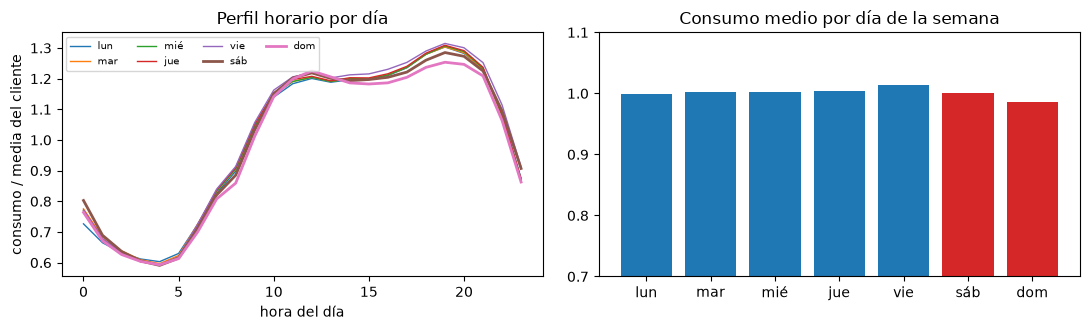

      0    1     2     3     4     5     6
4   0.6  0.6  0.59  0.59  0.59  0.59  0.59
12  1.2  1.2  1.20  1.21  1.22  1.22  1.23
19  1.3  1.3  1.31  1.31  1.31  1.29  1.25


In [6]:
pt_hol = holidays.Portugal(years=[2012, 2013, 2014])
rel = Y / Y.loc[:TRAIN_END].mean()
panel_rel = rel.mean(axis=1)                       # consumo relativo promedio del panel
days = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
prof = panel_rel.groupby([panel_rel.index.dayofweek, panel_rel.index.hour]).mean().unstack(0)
for d in range(7):
    ax[0].plot(prof.index, prof[d], label=days[d], lw=2 if d >= 5 else 1)
ax[0].set(xlabel="hora del día", ylabel="consumo / media del cliente", title="Perfil horario por día")
ax[0].legend(ncol=4, fontsize=7)
by_dow = panel_rel.groupby(panel_rel.index.dayofweek).mean()
ax[1].bar(days, by_dow, color=["C0"] * 5 + ["C3"] * 2)
ax[1].set(ylim=(0.7, 1.1), title="Consumo medio por día de la semana")
plt.tight_layout(); plt.savefig(FIGS / "perfiles.png", dpi=150); plt.show()
print(prof.round(2).loc[[4, 12, 19]])

### 2.2 Feriados de Portugal, Navidad y Año Nuevo

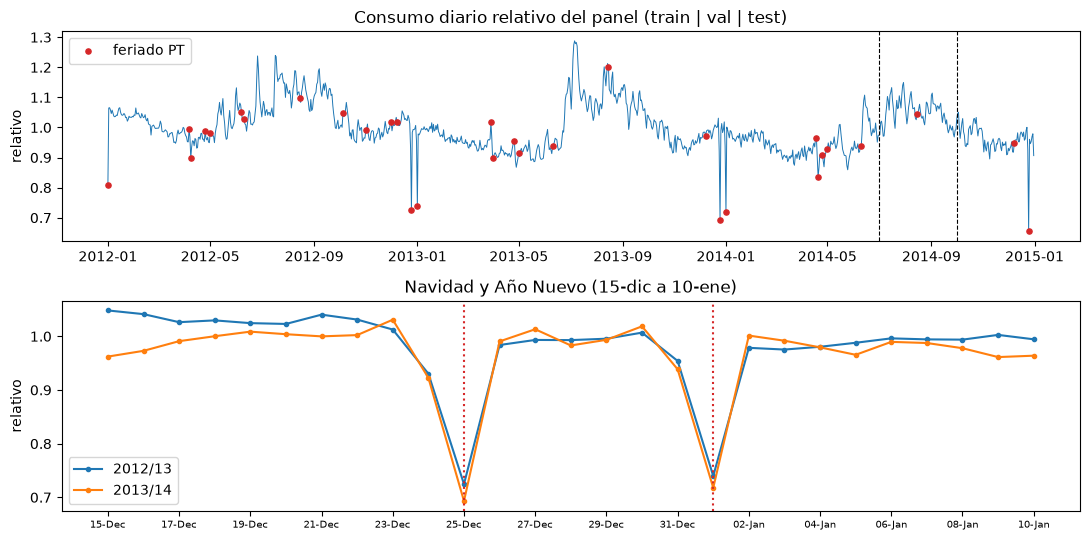

2012-12-24    0.919
2012-12-25    0.714
2012-12-31    0.966
2013-01-01    0.804
2013-12-24    0.939
2013-12-25    0.703
2013-12-31    0.969
2014-01-01    0.802
Name: ratio vs mismo día previo, dtype: float64
feriado (no fin de semana) vs mismo día previo: 0.951


In [7]:
daily = panel_rel.resample("D").mean()
hol_days = pd.DatetimeIndex([d for d in pt_hol if pd.Timestamp(d) in daily.index])
fig, ax = plt.subplots(2, 1, figsize=(11, 5.5))
ax[0].plot(daily.index, daily, lw=0.7)
ax[0].scatter(hol_days, daily.loc[hol_days], color="C3", s=14, zorder=3, label="feriado PT")
for s in (VAL_START, TEST_START):
    ax[0].axvline(s, color="k", ls="--", lw=0.8)
ax[0].set(title="Consumo diario relativo del panel (train | val | test)", ylabel="relativo"); ax[0].legend()
for y0 in (2012, 2013):
    w = daily.loc[f"{y0}-12-15":f"{y0 + 1}-01-10"]
    ax[1].plot(np.arange(len(w)), w.values, marker=".", label=f"{y0}/{y0 + 1 - 2000:02d}")
ax[1].set_xticks(range(0, 27, 2), [f"{d:%d-%b}" for d in pd.date_range("2013-12-15", periods=27)[::2]], fontsize=7)
ax[1].axvline(10, color="C3", ls=":"); ax[1].axvline(17, color="C3", ls=":")
ax[1].set(title="Navidad y Año Nuevo (15-dic a 10-ene)", ylabel="relativo"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIGS / "feriados.png", dpi=150); plt.show()

def vs_same_weekday(day):
    """Consumo del día / media del mismo día de la semana en las 3 semanas previas."""
    d = pd.Timestamp(day)
    return daily.loc[d] / daily.loc[[d - pd.Timedelta(weeks=k) for k in (1, 2, 3)]].mean()

rows = {d: vs_same_weekday(d) for d in ["2012-12-24", "2012-12-25", "2012-12-31", "2013-01-01",
                                       "2013-12-24", "2013-12-25", "2013-12-31", "2014-01-01"]}
print(pd.Series(rows, name="ratio vs mismo día previo").round(3))
print("feriado (no fin de semana) vs mismo día previo:",
      round(np.mean([vs_same_weekday(d) for d in hol_days if d.dayofweek < 5 and d > pd.Timestamp("2012-01-22")]), 3))

### 2.3 Escalas entre clientes y normalización

In [8]:
means = Y.loc[:TRAIN_END].mean()
print(f"consumo medio por cliente (kWh/h): min {means.min():.2f} | mediana {means.median():.1f} "
      f"| max {means.max():,.0f} | max/min = {means.max() / means.min():,.0f}×")
print(means.describe().round(1).to_dict())

consumo medio por cliente (kWh/h): min 8.28 | mediana 150.0 | max 3,906 | max/min = 472×
{'count': 100.0, 'mean': 391.9, 'std': 677.3, 'min': 8.3, '25%': 71.6, '50%': 150.0, '75%': 333.5, 'max': 3905.8}


Las escalas difieren en varios órdenes de magnitud, así que una normalización **global** (un solo μ, σ) deja a los
clientes chicos en ≈0 y la pérdida la dominan los grandes. Se usa **z-score por serie con estadísticos de
entrenamiento** (μᵢ, σᵢ calculados solo hasta 2014-06-30): todas las series quedan comparables para un modelo global y
no se usa información futura. La normalización **por ventana** (RevIN) se evalúa como iteración en §5.2: adapta el
nivel a cada ventana y ayuda ante cambios de nivel, a cambio de perder el nivel absoluto de la serie. Las métricas
siempre se calculan después de invertir la transformación, en kWh.

In [9]:
def fit_scaler(Y_train, kind="series"):
    """Estadísticos SOLO del bloque de entrenamiento. kind='series': z-score por cliente; 'global': uno para todos."""
    if kind == "global":
        return np.full(Y_train.shape[1], Y_train.values.mean()), np.full(Y_train.shape[1], Y_train.values.std())
    return Y_train.mean().values, Y_train.std().values

MU, SD = fit_scaler(Y.loc[:TRAIN_END])
Z = ((Y.values - MU) / SD).astype(np.float32)          # (T, N) panel escalado
print("Z train: media", Z[:t_val].mean().round(3), "std", Z[:t_val].std().round(3),
      "| Z test: media", Z[t_test:].mean().round(3))

Z train: media 0.0 std 1.0 | Z test: media -0.107


### 2.4 Covariables de calendario (conocidas a futuro)

Hora, día de la semana y mes se codifican con **seno/coseno** (`sin(2πk/P)`, `cos(2πk/P)`): 2 columnas por ciclo en
vez de 24+7+12 one-hot, y la distancia entre 23:00 y 00:00 (o diciembre y enero) es la misma que entre horas
consecutivas. El feriado es binario (1 todo el día). Las 7 columnas dependen solo del reloj y del calendario oficial,
así que se conocen para cualquier hora futura al emitir el pronóstico.

In [10]:
def calendar(idx):
    hol = np.array([d in pt_hol for d in idx.date], dtype=np.float32)
    feats = {}
    for name, k, P in [("hour", idx.hour, 24), ("dow", idx.dayofweek, 7), ("month", idx.month - 1, 12)]:
        feats[f"{name}_sin"] = np.sin(2 * np.pi * k / P)
        feats[f"{name}_cos"] = np.cos(2 * np.pi * k / P)
    feats["holiday"] = hol
    return pd.DataFrame(feats, index=idx).astype(np.float32)

CAL = calendar(Y.index)
C = CAL.values                                          # (T, 7)
print(CAL.loc["2013-12-25 00:00":"2013-12-25 02:00"].round(3))

                     hour_sin  hour_cos  dow_sin  dow_cos  month_sin  \
2013-12-25 00:00:00     0.000     1.000    0.975   -0.223       -0.5   
2013-12-25 01:00:00     0.259     0.966    0.975   -0.223       -0.5   
2013-12-25 02:00:00     0.500     0.866    0.975   -0.223       -0.5   

                     month_cos  holiday  
2013-12-25 00:00:00      0.866      1.0  
2013-12-25 01:00:00      0.866      1.0  
2013-12-25 02:00:00      0.866      1.0  


### 2.5 Dataset de ventanas deslizantes

`WindowDataset` indexa pares (serie, inicio del objetivo `t0`). Para cada par:
- `X`: `(L, 1 + 7)` = y escalado en `[t0-L, t0)` + calendario de esas horas
- `y`: `(H,)` = y escalado en `[t0, t0+H)`
- `cal_f`: `(H, 7)` = calendario de las horas objetivo (para el decoder del seq2seq y la MLP)

Los splits se definen por la **fecha del objetivo**: una ventana es de validación si sus H horas objetivo caen en
validación (su entrada puede venir de train, que es pasado). `__getitems__` arma el batch completo con indexado
vectorizado de NumPy, mucho más rápido que llamar `__getitem__` 512 veces.

In [11]:
def target_starts(split, L=L, H=H, stride=1, months=None):
    """Índices t0 cuyo objetivo [t0, t0+H) cae completo dentro del split. months: historia de train a usar."""
    lo, hi = {"train": (0, t_val), "val": (t_val, t_test), "test": (t_test, T)}[split]
    if split == "train" and months:
        lo = Y.index.get_loc(VAL_START - pd.DateOffset(months=months))
    first = lo + L if split == "train" else lo        # en train la entrada también debe caer en la historia usada
    return np.arange(first, hi - H + 1, stride)


class WindowDataset(Dataset):
    """Ventanas deslizantes sobre todas las series del panel."""

    def __init__(self, Z, C, t0s, L=L, H=H, series=None):
        self.Z, self.C, self.t0s, self.L, self.H = Z, C, np.asarray(t0s), L, H
        self.series = np.arange(Z.shape[1]) if series is None else np.asarray(series)

    def __len__(self):
        return len(self.series) * len(self.t0s)

    def __getitems__(self, idx):
        idx = np.asarray(idx)
        n, t0 = self.series[idx // len(self.t0s)], self.t0s[idx % len(self.t0s)]
        past = t0[:, None] + np.arange(-self.L, 0)
        fut = t0[:, None] + np.arange(self.H)
        x = np.concatenate([self.Z[past, n[:, None]][..., None], self.C[past]], axis=-1)
        return (torch.from_numpy(x), torch.from_numpy(self.Z[fut, n[:, None]]),
                torch.from_numpy(self.C[fut]), torch.from_numpy(n))

    def __getitem__(self, i):
        return tuple(t[0] for t in self.__getitems__([i]))


def loader(ds, batch_size=512, shuffle=False, num_samples=None):
    """DataLoader que entrega el batch ya armado por __getitems__ (collate identidad)."""
    sampler = torch.utils.data.RandomSampler(ds, num_samples=num_samples) if shuffle else None
    return DataLoader(ds, batch_size=batch_size, sampler=sampler, collate_fn=lambda b: b)


counts = {s: len(WindowDataset(Z, C, target_starts(s))) for s in ("train", "val", "test")}
print(pd.Series(counts, name=f"ventanas (L={L}, H={H}, stride 1 h, {N_CLIENTS} series)").map("{:,}".format))
print({s: f"{c // N_CLIENTS:,} por serie" for s, c in counts.items()})
x, y, cf, n = next(iter(loader(WindowDataset(Z, C, target_starts("train")), shuffle=True)))
print("X", tuple(x.shape), "| y", tuple(y.shape), "| cal_f", tuple(cf.shape), "| series", tuple(n.shape))

train    2,169,700
val        218,500
test       218,500
Name: ventanas (L=168, H=24, stride 1 h, 100 series), dtype: str
{'train': '21,697 por serie', 'val': '2,185 por serie', 'test': '2,185 por serie'}
X (512, 168, 8) | y (512, 24) | cal_f (512, 24, 7) | series (512,)


### 2.6 Auditoría de fugas

Regla: cada entrada de la red debe poder calcularse en el instante en que se emite el pronóstico (00:00 del día
objetivo, con datos hasta las 23:00 del día anterior). Las cuatro fugas vistas en clase y cómo las evita el pipeline:

In [12]:
times = Y.index
tr, va, te = (target_starts(s) for s in ("train", "val", "test"))

# 1) Split aleatorio de ventanas -> split cronológico por fecha del objetivo, sin solapes de objetivos
assert times[tr.max() + H - 1] <= TRAIN_END < times[va.min()]
assert times[va.max() + H - 1] <= VAL_END < times[te.min()]
rand = np.random.default_rng(0).permutation(np.r_[tr, va])[: len(va)]       # lo que haría un split aleatorio
print("1) split cronológico OK | con split aleatorio, % de 'val' con objetivo en train:",
      f"{(times[rand] <= TRAIN_END).mean():.0%}")

# 2) Escalar con toda la serie -> μ, σ solo de train; con la serie completa cambian (el futuro se filtra)
mu_all, sd_all = Y.mean().values, Y.std().values
assert np.allclose(MU, Y.loc[:TRAIN_END].mean().values)
print(f"2) scaler solo con train OK | |Δμ| medio si se usara toda la serie: {np.mean(np.abs(mu_all / MU - 1)):.1%}")

# 3) Early stopping con prueba -> los loaders de entrenamiento solo se construyen con 'train' y 'val';
#    train_model() (§5) verifica que la última hora objetivo de su loader de validación sea <= VAL_END
assert times[va.max() + H - 1] == VAL_END
print("3) validación termina en", VAL_END, "| prueba solo se toca dentro de backtest()")

# 4) Covariables mal alineadas -> X termina en t0-1 (dato real hasta 23:00); y y cal_f empiezan en t0
ds = WindowDataset(Z, C, te[::24])
x, y, cf, n = ds.__getitems__([0])
t0 = te[0]
assert times[t0] == TEST_START and times[t0 - 1].hour == 23
assert np.allclose(x[0, -1, 0], Z[t0 - 1, n[0]]) and np.allclose(y[0, 0], Z[t0, n[0]])
assert np.allclose(cf[0], calendar(times[t0:t0 + H]).values)          # calendario recalculado a futuro = cal_f
print("4) X:", times[t0 - L], "→", times[t0 - 1], "| y:", times[t0], "→", times[t0 + H - 1])

1) split cronológico OK | con split aleatorio, % de 'val' con objetivo en train: 91%
2) scaler solo con train OK | |Δμ| medio si se usara toda la serie: 1.1%
3) validación termina en 2014-09-30 23:00:00 | prueba solo se toca dentro de backtest()
4) X: 2014-09-24 00:00:00 → 2014-09-30 23:00:00 | y: 2014-10-01 00:00:00 → 2014-10-01 23:00:00


## 3. Investigación: herramientas para forecasting en PyTorch

**`nn.LSTM` / `nn.GRU`** procesan una secuencia con un estado recurrente. Parámetros: `input_size` (features por paso),
`hidden_size` (tamaño del estado), `num_layers` (capas apiladas), `batch_first=True` (entrada `(B, L, F)` en vez de
`(L, B, F)`), `dropout` (entre capas, solo si `num_layers > 1`). Salidas de la LSTM: `output` `(B, L, D·hidden)` con el
estado oculto de la última capa en cada paso; `h_n` `(D·num_layers, B, hidden)` el estado oculto final de cada capa;
`c_n` (solo LSTM) la celda de memoria final, misma forma. La GRU devuelve solo `(output, h_n)` (no tiene celda).

**`nn.Conv1d` dilatada y causal** (`in_channels, out_channels, kernel_size, dilation, padding`): la dilatación `d` salta
`d−1` pasos entre taps del kernel. Para que la salida en `t` no vea `t+1…` se rellena `(k−1)·d` solo a la izquierda
(`F.pad`) o se usa `padding=(k−1)·d` y se recortan los últimos pasos. Con capas de dilatación 1, 2, 4, …, 2ⁿ⁻¹ el campo
receptivo es `R = 1 + (k−1)·Σdᵢ = 1 + (k−1)(2ⁿ−1)`; con 2 convoluciones por bloque residual (TCN), `1 + 2(k−1)(2ⁿ−1)`.
Ej.: k = 3 y 7 bloques → R = 509 h, más de 3 semanas.

**`nn.TransformerEncoderLayer`** (`d_model` dimensión de los tokens, `nhead` cabezas de atención, `dim_feedforward`
ancho de la FFN, `dropout`, `batch_first`, `norm_first`): self-attention + FFN con residuales y LayerNorm. La atención es
invariante a permutaciones, así que el orden se inyecta sumando una **codificación posicional** a los embeddings antes
del encoder: `x = Linear(entrada) + PE[:L]`, con PE sinusoidal fija o una `nn.Parameter` aprendida. PatchTST aplica esto a
*parches* de la serie (16 pasos por token) en vez de a cada hora.

**StatsForecast / NeuralForecast (Nixtla)** reciben un DataFrame largo con `unique_id` (serie), `ds` (fecha) y `y`
(+ columnas exógenas). `StatsForecast(models, freq, n_jobs)` ajusta modelos locales (uno por serie);
`NeuralForecast(models, freq)` entrena modelos globales. `cross_validation(df, h, n_windows, step_size, refit, …)` hace
backtesting con origen móvil: `n_windows` = número de orígenes, `step_size` = distancia entre orígenes (24 → uno diario),
`refit` = re-entrenar en cada ventana (`True`), nunca (`False`) o cada k ventanas (entero). En StatsForecast,
`input_size` limita la historia de cada ajuste; en NeuralForecast, `val_size` reserva el bloque de early stopping.
Devuelve `unique_id, ds, cutoff, y, <modelo>`.

**Chronos-Bolt** (`chronos-forecasting`): `BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small")`;
`predict_quantiles(inputs, prediction_length, quantile_levels)` recibe un tensor `(B, contexto)` o una lista de tensores 1-D
(NaN = faltante), y devuelve `quantiles` `(B, H, Q)` y `mean` `(B, H)`. Bolt predice 9 cuantiles fijos (0.1…0.9) en
bloques de 64 pasos; horizontes más largos se generan de forma autorregresiva con la mediana.

**Conceptos.**
- *Local vs global*: un modelo local (ARIMA, ETS) ajusta parámetros por serie; uno global comparte pesos entre todas las
  series (normalizadas), aprende patrones comunes con muchos más datos y sirve para series nuevas, pero puede ignorar
  particularidades de cada cliente.
- *Teacher forcing*: al entrenar un modelo autorregresivo o un decoder seq2seq se le da como entrada el valor **real**
  del paso anterior; en inferencia recibe su propia predicción. Entrena rápido y estable, pero crea *exposure bias*: el
  modelo nunca vio sus propios errores y estos se acumulan con el horizonte.
- *RevIN*: normaliza cada ventana con su propia media y desviación (`x̃ = (x − μ_w)/σ_w`, con afín aprendible), la red
  predice en esa escala y la salida se des-normaliza con los mismos `μ_w, σ_w`. Si la serie cambia de nivel entre train y
  test, la red ve entradas con la misma distribución y el nivel nuevo se restituye al final.
- *Pinball loss*: `L_q(y, ŷ) = max(q(y − ŷ), (q − 1)(y − ŷ))`. Su minimizador es el cuantil q de la distribución
  condicional; promediada sobre varios q aproxima el CRPS. Con q = 0.5 es MAE/2.
- *MASE vs WAPE*: MASE = MAE / MAE del seasonal naive dentro de muestra, por serie: no depende de la escala, < 1 significa
  que se le gana al naive, y cada cliente pesa igual. WAPE = Σ|e| / Σ|y| sobre todo el panel: es un porcentaje de volumen,
  dominado por los clientes grandes (vista de negocio), e indefinido si Σ|y| = 0.

## 4. Protocolo de validación y métricas

`backtest(model)` es la única función de evaluación. Todo modelo implementa:
- `fit(train_end, val_end)`: entrena con datos ≤ `train_end`; el bloque `(train_end, val_end]` solo sirve para early
  stopping. Por defecto train ≤ 2014-06-30 y val hasta 2014-09-30: los pesos se entrenan una sola vez.
- `predict(origins, H)`: para cada origen `o` (00:00) pronostica `[o, o+H)` con datos `< o` (hasta las 23:00 previas).

Prueba: 92 orígenes diarios, 2014-10-01 … 2014-12-31. Las iteraciones de §5.2 usan los 92 orígenes de validación.
MASE usa como escala, por cliente, el MAE del seasonal naive de 24 h dentro del bloque de entrenamiento.

In [13]:
N = N_CLIENTS
TEST_ORIGINS = pd.date_range(TEST_START, END.normalize(), freq="D")
VAL_ORIGINS = pd.date_range(VAL_START, VAL_END.normalize(), freq="D")
assert len(TEST_ORIGINS) == len(VAL_ORIGINS) == 92
SCALE = Y.loc[:TRAIN_END].diff(24).abs().mean()           # escala MASE por cliente (kWh)
QS = (0.1, 0.5, 0.9)

def origins_for(H, origins=TEST_ORIGINS, end=END):
    """Orígenes cuyo horizonte completo cae dentro del bloque (H=168 -> 86 orígenes de prueba)."""
    return origins[origins + pd.Timedelta(hours=H - 1) <= end]

def to_long(P, origins, H):
    """(n_orig, N, H) -> formato largo unique_id, ds, origin, h, y, y_hat [, q10, q50, q90]."""
    t_o = Y.index.get_indexer(origins)
    tt = np.broadcast_to(t_o[:, None, None] + np.arange(H), (len(t_o), N, H)).ravel()
    nn_ = np.broadcast_to(np.arange(N)[None, :, None], (len(t_o), N, H)).ravel()
    fc = pd.DataFrame({"unique_id": pd.Categorical(np.array(CLIENTS)[nn_]), "ds": Y.index[tt],
                       "origin": np.repeat(origins, N * H), "h": np.tile(np.arange(1, H + 1), len(t_o) * N),
                       "y": Y.values[tt, nn_].astype(np.float32), "y_hat": P["y_hat"].ravel().astype(np.float32)})
    for q in QS:
        if f"q{int(q * 100)}" in P:
            fc[f"q{int(q * 100)}"] = P[f"q{int(q * 100)}"].ravel().astype(np.float32)
    return fc

def evaluate(fc):
    """Métricas en kWh agregadas sobre todos los clientes y orígenes."""
    e = fc.y_hat - fc.y
    ae = e.abs()
    sae = ae / fc.unique_id.map(SCALE).astype(float)           # error escalado (MASE puntual)
    nz = fc.y > 0
    xm = fc.ds.between("2014-12-22", "2014-12-28 23:00")
    m = {"MAE": ae.mean(), "RMSE": np.sqrt((e ** 2).mean()), "WAPE": ae.sum() / fc.y.abs().sum(),
         "MAPE": (ae[nz] / fc.y[nz]).mean(), "MASE": sae.mean(), "MASE_xmas": sae[xm].mean() if xm.any() else np.nan}
    if "q10" in fc:
        pl = [np.maximum(q * (fc.y - fc[f"q{int(q * 100)}"]), (q - 1) * (fc.y - fc[f"q{int(q * 100)}"])).mean() for q in QS]
        m["pinball"] = np.mean(pl)
        m["cov80"] = ((fc.y >= fc.q10) & (fc.y <= fc.q90)).mean()
    return m

def per_client(fc):
    e = fc.y_hat - fc.y
    g = pd.DataFrame({"unique_id": fc.unique_id, "ae": e.abs(), "se": e ** 2, "ape": e.abs() / fc.y.where(fc.y > 0)})
    out = g.groupby("unique_id", observed=True).agg(MAE=("ae", "mean"), MSE=("se", "mean"), MAPE=("ape", "mean"))
    out["RMSE"] = np.sqrt(out.pop("MSE"))
    out["MASE"] = out.MAE / SCALE[out.index].values
    return out

def by_step(fc, col="h"):
    """MAE (kWh) y MASE por paso del horizonte (col='h') o por hora del día (col='hour')."""
    ae = (fc.y_hat - fc.y).abs()
    key = fc.ds.dt.hour if col == "hour" else fc[col]
    return pd.DataFrame({"MAE": ae, "MASE": ae / fc.unique_id.map(SCALE).astype(float)}).groupby(key.values).mean()

def peak_mem_mb():
    return torch.mps.driver_allocated_memory() / 2 ** 20 if DEVICE.type == "mps" else np.nan

def backtest(model, origins=TEST_ORIGINS, H=H, train_end=TRAIN_END, val_end=VAL_END, fit=True):
    """Protocolo único: entrena una vez y pronostica H horas desde cada origen con datos < origen."""
    t = time.perf_counter()
    if fit:
        model.fit(train_end, val_end)
    train_s = time.perf_counter() - t
    t = time.perf_counter()
    P = model.predict(origins, H)
    infer_s = time.perf_counter() - t
    assert P["y_hat"].shape == (len(origins), N, H) and np.isfinite(P["y_hat"]).all()
    return {"fc": to_long(P, origins, H), "train_s": train_s, "infer_s": infer_s,
            "n_params": getattr(model, "n_params", (0, 0)), "history": getattr(model, "history", None),
            "epoch_s": getattr(model, "epoch_s", None), "peak_mem_mb": getattr(model, "peak_mem", np.nan)}

REG = {}                                                         # nombre -> fila de la tabla comparativa
FCS = {}                                                         # nombre -> pronósticos de prueba (H=24)

def register(name, res, family, L_=L, strategy="multi-salida", covariates="no", H_=H, hw="CPU"):
    m = evaluate(res["fc"])
    if H_ != H:                                                  # solo agrega MASE con H=168 a la fila existente
        REG.setdefault(name, {})["MASE_H168"] = m["MASE"]
        return m
    FCS[name] = res["fc"]
    tot, trn = res["n_params"]
    REG[name] = {**REG.get(name, {}), "familia": family, "L": L_, "estrategia": strategy, "covariables": covariates,
                 "params": tot, "entrenables": trn, "train_s": res["train_s"], "infer_s": res["infer_s"],
                 "hardware": hw, **m}
    return m

def show(names=None):
    df = pd.DataFrame(REG).T
    df = df.loc[names] if names else df
    cols = [c for c in ["MAE", "RMSE", "WAPE", "MAPE", "MASE", "MASE_xmas", "MASE_H168", "pinball", "cov80",
                        "train_s", "infer_s"] if c in df]
    return df[cols].astype(float).sort_values("MASE").round(3)

### 4.1 Baselines (StatsForecast)

Naive, seasonal naive de 24 h y 168 h y MSTL (estacionalidades 24 y 168, tendencia con AutoETS). Son modelos locales: en
cada origen se re-ajustan con la historia de esa serie, por lo que `fit()` no hace nada y todo el costo está en
`predict()`. MSTL usa las últimas 6 semanas (`input_size=1008`) para que 9,200 ajustes sean viables.

In [14]:
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, MSTL

def long_df(Yw):
    return Yw.reset_index(names="ds").melt("ds", var_name="unique_id", value_name="y")

class SFModel:
    """Adaptador de un modelo de StatsForecast al protocolo fit/predict."""

    def __init__(self, model, input_size=None):
        self.model, self.input_size = model, input_size

    def fit(self, train_end, val_end):
        pass                                                     # modelo local: se ajusta en cada origen

    def predict(self, origins, H):
        df = long_df(Y.loc[:origins[-1] + pd.Timedelta(hours=H - 1)])
        sf = StatsForecast(models=[self.model], freq="h", n_jobs=-1)
        cv = sf.cross_validation(df=df, h=H, n_windows=len(origins), step_size=24, input_size=self.input_size)
        cv = cv.sort_values(["cutoff", "unique_id", "ds"])
        assert (pd.DatetimeIndex(cv.cutoff.unique()) == origins - pd.Timedelta("1h")).all()
        assert list(cv.unique_id.iloc[: N * H: H]) == CLIENTS
        return {"y_hat": cv.iloc[:, -1].values.reshape(len(origins), N, H)}

BASELINES = {"Naive": (Naive(), None), "SNaive24": (SeasonalNaive(24), None),
             "SNaive168": (SeasonalNaive(168), None), "MSTL": (MSTL(season_length=[24, 168]), 24 * 7 * 6)}
for name, (mdl, isz) in BASELINES.items():
    res = cached(f"bt_{name}", lambda: backtest(SFModel(mdl, isz)))
    register(name, res, "Baseline", L_="—" if name != "MSTL" else 1008, strategy="directa (local)")
    res168 = cached(f"bt_{name}_H168", lambda: backtest(SFModel(mdl, isz), origins_for(168), 168))
    register(name, res168, "Baseline", H_=168)
show()

,MAE,RMSE,WAPE,MAPE,MASE,MASE_xmas,MASE_H168,train_s,infer_s
MSTL,29.822,99.278,0.080,0.104,0.931,2.044,1.083,0.0,340.868
SNaive24,32.511,118.684,0.088,0.120,1.040,2.261,1.208,0.0,11.779
SNaive168,33.585,116.377,0.091,0.114,1.124,1.647,1.129,0.0,18.002
Naive,133.870,360.047,0.361,0.406,4.191,4.197,4.227,0.0,17.560


### 4.2 MAPE y clientes de consumo bajo

El MAPE divide cada error entre el valor real: con consumos cercanos a cero un error pequeño en kWh se vuelve un
porcentaje enorme. El problema no es la media del cliente sino las horas en que su consumo cae casi a cero (cortes,
cierres): esas pocas horas dominan su MAPE.

In [15]:
fc = FCS["SNaive168"]
ape = (fc.y_hat - fc.y).abs() / fc.y.where(fc.y > 0)
pc = per_client(fc).join(means.rename("media_kWh"))
pc["horas_y<1kWh_%"] = 100 * (fc.y < 1).groupby(fc.unique_id, observed=True).mean()
print(pc.sort_values("MAPE", ascending=False).head(5).round(2))
print("Spearman MAPE vs consumo medio:", pc.MAPE.corr(pc.media_kWh, method="spearman").round(2),
      "| vs % de horas < 1 kWh:", pc.MAPE.corr(pc["horas_y<1kWh_%"], method="spearman").round(2))
print(f"horas con y < 1 kWh: {(fc.y < 1).mean():.2%} | APE máximo: {ape.max():,.0f} (= {100 * ape.max():,.0f} %)"
      f" | MAPE {ape.mean():.3f} -> sin horas < 1 kWh: {ape[fc.y >= 1].mean():.3f}")

                  MAE  MAPE        RMSE  MASE  media_kWh  horas_y<1kWh_%
unique_id                                                               
MT_036      12.870000  0.52   20.190001  0.98      36.49            0.00
MT_348       6.880000  0.49   12.850000  0.53      19.04           43.93
MT_345     171.750000  0.45  279.679993  1.43    2120.08            0.00
MT_130      14.270000  0.31   35.400002  0.35      42.91           53.62
MT_359      17.040001  0.24   25.180000  1.18     107.61            0.00
Spearman MAPE vs consumo medio: -0.03 | vs % de horas < 1 kWh: 0.13
horas con y < 1 kWh: 1.04% | APE máximo: 804 (= 80,400 %) | MAPE 0.114 -> sin horas < 1 kWh: 0.113


### 4.3 LightGBM global con rezagos

Un solo modelo para los 100 clientes (series en z-score). Features de la fila `t`: rezagos 1–24 y 168 de `y` y
calendario de `t` (hora, día, mes, feriado). Se entrena a un paso y se pronostica de forma **recursiva**: para el paso
k del día, los rezagos 1…k−1 son predicciones propias (nunca datos reales posteriores al origen). Early stopping con la
pérdida a un paso en validación.

In [16]:
import lightgbm as lgb

LAGS = list(range(1, 25)) + [168]
CALI = np.column_stack([Y.index.hour, Y.index.dayofweek, Y.index.month, CAL.holiday]).astype(np.float32)

class LGBMRecursive:
    def __init__(self, months=None, seed=SEED, **params):
        self.months = months
        self.params = {"objective": "l2", "learning_rate": 0.05, "num_leaves": 127, "min_data_in_leaf": 200,
                       "feature_fraction": 0.9, "bagging_fraction": 0.8, "bagging_freq": 1, "seed": seed,
                       "verbose": -1, "num_threads": 0, **params}

    def _rows(self, t_idx):
        tt, nn_ = np.repeat(t_idx, N), np.tile(np.arange(N), len(t_idx))
        X = np.column_stack([Z[tt - k, nn_] for k in LAGS] + [CALI[tt]])
        return X, Z[tt, nn_]

    def fit(self, train_end, val_end):
        te, ve = Y.index.get_loc(train_end), Y.index.get_loc(val_end)
        start = Y.index.get_loc(train_end + pd.Timedelta("1h") - pd.DateOffset(months=self.months)) if self.months else 0
        Xtr, ytr = self._rows(np.arange(start + 168, te + 1))
        Xva, yva = self._rows(np.arange(te + 1, ve + 1))
        cat = list(range(len(LAGS), len(LAGS) + 3))
        dtr = lgb.Dataset(Xtr, ytr, categorical_feature=cat)
        self.booster = lgb.train(self.params, dtr, num_boost_round=3000,
                                 valid_sets=[lgb.Dataset(Xva, yva, reference=dtr)],
                                 callbacks=[lgb.early_stopping(50, verbose=False)])
        dump = self.booster.dump_model()["tree_info"]
        nodes = sum(2 * t["num_leaves"] - 1 for t in dump)        # nodos (splits + hojas) como "parámetros"
        self.n_params = (nodes, nodes)

    def predict(self, origins, H):
        t_o = Y.index.get_indexer(origins)
        B = np.empty((len(t_o), N, 168 + H), dtype=np.float32)
        B[:, :, :168] = Z[t_o[:, None] + np.arange(-168, 0)].transpose(0, 2, 1)
        for k in range(H):
            lags = np.stack([B[:, :, 168 + k - j] for j in LAGS], -1)                 # (n_o, N, 25)
            cal = np.broadcast_to(CALI[t_o + k][:, None, :], (len(t_o), N, CALI.shape[1]))
            X = np.concatenate([lags, cal], -1).reshape(-1, len(LAGS) + CALI.shape[1])
            B[:, :, 168 + k] = self.booster.predict(X, num_threads=0).reshape(len(t_o), N)
        return {"y_hat": B[:, :, 168:] * SD[None, :, None] + MU[None, :, None]}

def lgbm_runs():
    m = LGBMRecursive()
    r24 = backtest(m)
    r168 = backtest(m, origins_for(168), 168, fit=False)
    r168["train_s"] = r24["train_s"]
    return r24, r168, m

r24, r168, lgbm = cached("bt_LightGBM", lgbm_runs)
register("LightGBM", r24, "Árboles", L_=168, strategy="recursiva", covariates="calendario")
register("LightGBM", r168, "Árboles", H_=168)
print("árboles:", lgbm.booster.best_iteration, "| nodos:", r24["n_params"][0], "| entrenamiento", round(r24["train_s"]), "s")
show()

árboles: 2981 | nodos: 754193 | entrenamiento 222 s


,MAE,RMSE,WAPE,MAPE,MASE,MASE_xmas,MASE_H168,train_s,infer_s
LightGBM,27.566,95.983,0.074,0.094,0.878,1.727,1.081,221.702,20.747
MSTL,29.822,99.278,0.080,0.104,0.931,2.044,1.083,0.000,340.868
SNaive24,32.511,118.684,0.088,0.120,1.040,2.261,1.208,0.000,11.779
SNaive168,33.585,116.377,0.091,0.114,1.124,1.647,1.129,0.000,18.002
Naive,133.870,360.047,0.361,0.406,4.191,4.197,4.227,0.000,17.560


**Comprobación de fugas en `predict()`.** Se pronostica desde un origen reemplazando por NaN todo dato ≥ origen: si el
modelo leyera el futuro saldría NaN o cambiaría el pronóstico. La misma prueba se aplica a los modelos propios de §5.

In [17]:
def future_masked(model, origin=TEST_ORIGINS[10], H=H):
    """Pronóstico con el futuro borrado == pronóstico normal  =>  el modelo solo usa datos < origen."""
    global Y, Z
    Y0, Z0 = Y, Z
    t = Y0.index.get_loc(origin)
    normal = model.predict(pd.DatetimeIndex([origin]), H)["y_hat"]
    Y, Z = Y0.copy(), Z0.copy()
    Y.iloc[t:], Z[t:] = np.nan, np.nan
    try:
        masked = model.predict(pd.DatetimeIndex([origin]), H)["y_hat"]
    finally:
        Y, Z = Y0, Z0
    assert np.isfinite(masked).all() and np.allclose(normal, masked, rtol=1e-4, atol=1e-3)
    return f"{type(model).__name__}: sin fuga hacia el futuro"

print(future_masked(lgbm))

LGBMRecursive: sin fuga hacia el futuro


## 5. Modelos propios en PyTorch

Todas las redes reciben `X` `(B, L, 8)` (y normalizado + 7 columnas de calendario) y `cal_f` `(B, H, 7)` y devuelven
`(B, H)` en la escala normalizada. Pérdida L1 (las métricas objetivo son MAE/MASE). Con `revin=True` la red se envuelve con
RevIN sobre el canal y.

| Modelo | Arquitectura | Estrategia | Covariables |
|---|---|---|---|
| MLP | flatten(X) ‖ flatten(cal_f) → 512 → 512 → H | multi-salida | pasado + futuro |
| DLinear | media móvil (k=25) separa tendencia/estacional; Linear(L→H) para cada una | multi-salida | no (solo y) |
| NLinear | resta el último valor, Linear(L→H), lo suma | multi-salida | no (solo y) |
| LSTM | LSTM(8→h, capas) → h_T ‖ flatten(cal_f) → Linear → H | multi-salida | pasado + futuro |
| LSTM-AR | LSTM → y_{t+1}; en inferencia realimenta ŷ con el calendario conocido | autorregresiva | pasado + futuro |
| Seq2seq | encoder LSTM(pasado) → estado → decoder LSTM(cal_f) → Linear por paso | encoder–decoder | pasado + futuro (decoder) |

La LSTM-AR se entrena con *teacher forcing*: la secuencia de entrada se extiende con los valores reales del horizonte
y en cada posición se predice el siguiente valor. El decoder del seq2seq recibe solo el calendario de las horas objetivo
(no consume y), así que no tiene exposure bias y sus 24 salidas se producen en una sola pasada.

In [18]:
import copy, gc
import torch.nn.functional as F

def free_mps():
    """Devuelve al sistema la caché de MPS entre entrenamientos (la RAM es compartida con la GPU)."""
    gc.collect()
    if DEVICE.type == "mps":
        torch.mps.empty_cache()

class RevIN(nn.Module):
    """Reversible instance normalization del canal y de cada ventana (con afín aprendible)."""

    def __init__(self):
        super().__init__()
        self.w, self.b = nn.Parameter(torch.ones(1)), nn.Parameter(torch.zeros(1))

    def norm(self, x):
        y = x[..., :1]
        self.mu, self.sd = y.mean(1, keepdim=True), y.std(1, keepdim=True) + 1e-4
        return torch.cat([(y - self.mu) / self.sd * self.w + self.b, x[..., 1:]], -1)

    def norm_y(self, y):
        return (y - self.mu[:, :, 0]) / self.sd[:, :, 0] * self.w + self.b

    def denorm(self, out):
        return (out - self.b) / (self.w + 1e-8) * self.sd[:, :, 0] + self.mu[:, :, 0]


class Forecaster(nn.Module):
    """Base: forward(x, cal_f) -> (B, H). Las subclases implementan core()."""

    def __init__(self, revin=False):
        super().__init__()
        self.rev = RevIN() if revin else None

    def forward(self, x, cf):
        out = self.core(self.rev.norm(x) if self.rev else x, cf)
        return self.rev.denorm(out) if self.rev else out

    def train_loss(self, x, y, cf):
        return F.l1_loss(self(x, cf), y)


class MLP(Forecaster):
    def __init__(self, L, H, hidden=512, dropout=0.1, revin=False):
        super().__init__(revin)
        self.net = nn.Sequential(nn.Linear(L * 8 + H * 7, hidden), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, H))

    def core(self, x, cf):
        return self.net(torch.cat([x.flatten(1), cf.flatten(1)], 1))


class DLinear(Forecaster):
    """Zeng et al. (2023): Linear(tendencia) + Linear(estacional); tendencia = media móvil de k pasos."""

    def __init__(self, L, H, kernel=25, revin=False):
        super().__init__(revin)
        self.k, self.trend, self.season = kernel, nn.Linear(L, H), nn.Linear(L, H)

    def core(self, x, cf):
        y = x[..., 0]
        pad = F.pad(y[:, None], ((self.k - 1) // 2, self.k // 2), mode="replicate")
        trend = F.avg_pool1d(pad, self.k, stride=1)[:, 0]
        return self.trend(trend) + self.season(y - trend)


class NLinear(Forecaster):
    """Resta el último valor observado, Linear(L->H), y lo vuelve a sumar."""

    def __init__(self, L, H, revin=False):
        super().__init__(revin)
        self.lin = nn.Linear(L, H)

    def core(self, x, cf):
        last = x[:, -1:, 0]
        return self.lin(x[..., 0] - last) + last


class LSTMMulti(Forecaster):
    """Multi-salida: estado final de la LSTM + calendario futuro -> una capa densa con los H pasos."""

    def __init__(self, L, H, hidden=128, layers=2, dropout=0.1, revin=False):
        super().__init__(revin)
        self.lstm = nn.LSTM(8, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0)
        self.head = nn.Linear(hidden + H * 7, H)

    def core(self, x, cf):
        _, (h, _) = self.lstm(x)
        return self.head(torch.cat([h[-1], cf.flatten(1)], 1))


class LSTMAR(Forecaster):
    """Autorregresiva: predice y_{t+1}; en inferencia realimenta su propia predicción."""

    def __init__(self, L, H, hidden=128, layers=2, dropout=0.1, revin=False):
        super().__init__(revin)
        self.H = H
        self.lstm = nn.LSTM(8, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0)
        self.head = nn.Linear(hidden, 1)

    def core(self, x, cf):
        out, state = self.lstm(x)
        yk = self.head(out[:, -1])                                  # ŷ_{t0}
        preds = [yk]
        for k in range(self.H - 1):                                 # entrada [ŷ_{t0+k}, cal_{t0+k}] -> ŷ_{t0+k+1}
            out, state = self.lstm(torch.cat([yk, cf[:, k]], -1)[:, None], state)
            yk = self.head(out[:, -1])
            preds.append(yk)
        return torch.cat(preds, 1)

    def train_loss(self, x, y, cf):
        """Teacher forcing: la entrada se extiende con los y reales del horizonte (desplazados un paso)."""
        if self.rev:
            x = self.rev.norm(x)
            y = self.rev.norm_y(y)
        seq = torch.cat([x, torch.cat([y[:, :-1, None], cf[:, :-1]], -1)], 1)
        out, _ = self.lstm(seq)
        return F.l1_loss(self.head(out)[..., 0], torch.cat([x[:, 1:, 0], y], 1))


class Seq2Seq(Forecaster):
    """Encoder LSTM sobre el pasado; decoder LSTM alimentado con el calendario de las H horas objetivo."""

    def __init__(self, L, H, hidden=128, layers=2, dropout=0.1, revin=False):
        super().__init__(revin)
        d = dropout if layers > 1 else 0
        self.enc = nn.LSTM(8, hidden, layers, batch_first=True, dropout=d)
        self.dec = nn.LSTM(7, hidden, layers, batch_first=True, dropout=d)
        self.head = nn.Linear(hidden, 1)

    def core(self, x, cf):
        _, state = self.enc(x)
        out, _ = self.dec(cf, state)
        return self.head(out)[..., 0]


ARCH = {"MLP": MLP, "DLinear": DLinear, "NLinear": NLinear, "LSTM": LSTMMulti, "LSTM-AR": LSTMAR, "Seq2seq": Seq2Seq}
x, y, cf, n = next(iter(loader(WindowDataset(Z, C, target_starts("train")), batch_size=4)))
for name, cls in ARCH.items():
    assert cls(L, H)(x, cf).shape == (4, H), name
print("formas OK:", list(ARCH))

formas OK: ['MLP', 'DLinear', 'NLinear', 'LSTM', 'LSTM-AR', 'Seq2seq']


### Entrenamiento

`TorchModel` adapta cualquier arquitectura al protocolo `fit/predict`. `fit()` muestrea en cada epoch 100k ventanas al azar
del bloque de entrenamiento (de 2.17M posibles con stride 1) y al final de cada epoch pronostica los 92 orígenes de
**validación** (00:00 de cada día) para la pérdida, el MAE y el MASE de validación. Máximo 15 epochs, early stopping con
paciencia 3 sobre la pérdida de validación y se restauran los mejores pesos. La prueba nunca se usa aquí. Batch de 512: en
MPS la LSTM con L = 168 procesa ~2,800 muestras/s con 3.4 GB, contra ~400 muestras/s en CPU. Con batch 1024 necesita
6.7 GB y, con la memoria del equipo casi llena (swap), cada epoch tardó 3–5× más (iteración `LSTM-b1024`).

In [19]:
def norm_panel(kind):
    """Panel normalizado con estadísticos de train. 'series' y 'revin' usan z-score por serie; 'global' uno solo."""
    mu, sd = fit_scaler(Y.loc[:TRAIN_END], "global" if kind == "global" else "series")
    return ((Y.values - mu) / sd).astype(np.float32), mu, sd

def count_params(net):
    ps = list(net.parameters())
    return sum(p.numel() for p in ps), sum(p.numel() for p in ps if p.requires_grad)

class TorchModel:
    def __init__(self, arch, L=L, H=H, months=None, norm="series", lr=1e-3, batch=512, epochs=15,
                 samples=100_000, patience=3, seed=SEED, series=None, **net_kw):
        self.arch, self.L, self.H, self.months, self.norm, self.net_kw = arch, L, H, months, norm, net_kw
        self.lr, self.batch, self.epochs, self.samples, self.patience, self.seed = lr, batch, epochs, samples, patience, seed
        self.series = np.arange(N) if series is None else np.asarray(series)

    def build(self):
        torch.manual_seed(self.seed)
        self.net = ARCH[self.arch](self.L, self.H, revin=self.norm == "revin", **self.net_kw).to(DEVICE)
        self.n_params = count_params(self.net)
        return self

    def _inputs(self, Zn, t0s):
        """Solo entradas (X, cal_f) para los orígenes t0s: lee y en [t0-L, t0) y nunca y >= t0."""
        n, t0 = np.tile(self.series, len(t0s)), np.repeat(t0s, len(self.series))
        past = t0[:, None] + np.arange(-self.L, 0)
        x = np.concatenate([Zn[past, n[:, None]][..., None], C[past]], -1)
        return torch.from_numpy(x), torch.from_numpy(C[t0[:, None] + np.arange(self.H)])

    @torch.no_grad()
    def _forecast(self, Zn, t0s, bs=1024):
        self.net.eval()
        x, cf = self._inputs(Zn, t0s)
        out = torch.cat([self.net(x[i:i + bs].to(DEVICE), cf[i:i + bs].to(DEVICE)).cpu() for i in range(0, len(x), bs)])
        out = out.numpy().reshape(len(t0s), len(self.series), self.H)
        return out * self.sd[self.series][None, :, None] + self.mu[self.series][None, :, None]      # kWh

    def fit(self, train_end, val_end):
        np.random.seed(self.seed)
        Zn, self.mu, self.sd = norm_panel(self.norm)
        te, ve = Y.index.get_loc(train_end) + 1, Y.index.get_loc(val_end) + 1
        start = (Y.index.get_loc(train_end + pd.Timedelta("1h") - pd.DateOffset(months=self.months))
                 if self.months else 0)
        tr = np.arange(start + self.L, te - self.H + 1)              # objetivos completos dentro de train
        va = np.arange(te, ve - self.H + 1, 24)                      # orígenes diarios 00:00 de validación
        assert Y.index[tr[-1] + self.H - 1] <= train_end and Y.index[va[-1] + self.H - 1] <= val_end  # fuga 3
        ds = WindowDataset(Zn, C, tr, self.L, self.H, self.series)
        dl = loader(ds, self.batch, shuffle=True, num_samples=min(self.samples, len(ds)))
        y_va = Y.values[va[:, None] + np.arange(self.H)][:, :, self.series].transpose(0, 2, 1)
        sd_s, sc = self.sd[self.series][None, :, None], SCALE.values[self.series][None, :, None]
        self.build()
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr)
        self.history, best, wait, self.peak_mem = [], np.inf, 0, 0.0
        for ep in range(1, self.epochs + 1):
            t, tl, nb_ = time.perf_counter(), torch.zeros((), device=DEVICE), 0
            self.net.train()
            for x, y, cf, _ in dl:
                loss = self.net.train_loss(x.to(DEVICE), y.to(DEVICE), cf.to(DEVICE))
                opt.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(self.net.parameters(), 1.0)
                opt.step()
                tl, nb_ = tl + loss.detach(), nb_ + 1
            self.peak_mem = max(self.peak_mem, peak_mem_mb())
            err = self._forecast(Zn, va) - y_va
            vl = np.abs(err / sd_s).mean()                               # L1 en escala normalizada
            self.history.append({"epoch": ep, "train_loss": tl.item() / nb_, "val_loss": vl,
                                 "val_MAE": np.abs(err).mean(), "val_MASE": np.abs(err / sc).mean(),
                                 "epoch_s": time.perf_counter() - t})
            if vl < best - 1e-4:
                best, wait, state = vl, 0, copy.deepcopy(self.net.state_dict())
            else:
                wait += 1
                if wait >= self.patience:
                    break
        self.net.load_state_dict(state)
        self.epoch_s = np.mean([h["epoch_s"] for h in self.history])
        del dl, ds, opt, state
        free_mps()

    def predict(self, origins, H):
        assert H == self.H
        Zn, self.mu, self.sd = norm_panel(self.norm)                     # desde el Y actual
        return {"y_hat": self._forecast(Zn, Y.index.get_indexer(origins))}

ITERS = {}
VAL_MASE, MAKE = {}, {}                  # modelo registrado -> MASE de validación / fábrica para re-entrenar

def iterate(name, arch, **cfg):
    """Una iteración de §5.2: train + early stopping/selección en validación (92 orígenes). No toca la prueba."""
    def go():
        m = TorchModel(arch, **cfg)
        res = backtest(m, origins_for(m.H, VAL_ORIGINS, VAL_END), m.H)
        res["val"] = evaluate(res.pop("fc"))
        res["state"] = {k: v.cpu() for k, v in m.net.state_dict().items()}
        return res
    res = cached(f"it_{name}", go)
    free_mps()
    ITERS[name] = {"arch": arch, "cfg": cfg, **res}
    h = res["history"][-1]
    print(f"{name:16s} epochs {h['epoch']:2d} | val MAE {res['val']['MAE']:7.2f} | val MASE {res['val']['MASE']:.3f} "
          f"| {res['train_s']:5.0f} s | params {res['n_params'][0]:,}")
    return res

def load_iter(name):
    """Reconstruye el TorchModel ya entrenado de una iteración (pesos del caché)."""
    it = ITERS[name]
    m = TorchModel(it["arch"], **it["cfg"]).build()
    m.net.load_state_dict(it["state"])
    _, m.mu, m.sd = norm_panel(m.norm)
    return m

def test_torch(name, it_name, family, strategy, covariates):
    """Evalúa una sola vez en prueba la configuración elegida en validación (mismos pesos, sin re-entrenar)."""
    it = ITERS[it_name]
    def go():
        res = backtest(load_iter(it_name), TEST_ORIGINS, it["cfg"].get("H", H), fit=False)
        res.update({k: it[k] for k in ("train_s", "n_params", "history", "epoch_s", "peak_mem_mb")})
        return res
    res = cached(f"bt_{name}", go)
    register(name, res, family, L_=it["cfg"].get("L", L), strategy=strategy, covariates=covariates, hw=HARDWARE)
    VAL_MASE[name], MAKE[name] = it["val"]["MASE"], lambda seed=SEED: TorchModel(it["arch"], seed=seed, **it["cfg"])
    return res

print(future_masked(TorchModel("LSTM-AR").build()))         # la AR realimenta predicciones: el caso más delicado

TorchModel: sin fuga hacia el futuro


### 5.2 Iteraciones de hiperparámetros

Base LSTM: L = 168, H = 24, 30 meses de historia, z-score por serie, hidden 128, 2 capas, dropout 0.1, lr 1e-3, batch 512.
Cada iteración cambia un factor. Para DLinear se repiten los barridos de L y de historia (la curva de historia de §6
necesita DLinear, LSTM, LightGBM y PatchTST).

In [20]:
LSTM_BASE = dict(L=168, hidden=128, layers=2, dropout=0.1, lr=1e-3, batch=512, norm="series")
LSTM_RUNS = {"LSTM-base": {}, "LSTM-L48": {"L": 48}, "LSTM-L336": {"L": 336},
             "LSTM-3m": {"months": 3}, "LSTM-12m": {"months": 12},
             "LSTM-global": {"norm": "global"}, "LSTM-revin": {"norm": "revin"},
             "LSTM-h256": {"hidden": 256}, "LSTM-lr3e-3": {"lr": 3e-3}, "LSTM-b1024": {"batch": 1024}}
for name, ch in LSTM_RUNS.items():
    iterate(name, "LSTM", **{**LSTM_BASE, **ch})

LSTM-base        epochs 15 | val MAE   31.39 | val MASE 0.991 |   497 s | params 209,880
LSTM-L48         epochs 15 | val MAE   31.12 | val MASE 0.991 |   131 s | params 209,880
LSTM-L336        epochs 15 | val MAE   30.93 | val MASE 0.992 |  1865 s | params 209,880
LSTM-3m          epochs 10 | val MAE   36.99 | val MASE 1.098 |   239 s | params 209,880


LSTM-12m         epochs 15 | val MAE   31.35 | val MASE 0.996 |   337 s | params 209,880


LSTM-global      epochs 15 | val MAE   39.56 | val MASE 1.546 |   328 s | params 209,880
LSTM-revin       epochs 15 | val MAE   31.18 | val MASE 0.977 |   315 s | params 209,882
LSTM-h256        epochs 15 | val MAE   29.81 | val MASE 0.946 |  1486 s | params 808,920
LSTM-lr3e-3      epochs 15 | val MAE   29.36 | val MASE 0.940 |   273 s | params 209,880


LSTM-b1024       epochs 15 | val MAE   33.39 | val MASE 1.036 |  2652 s | params 209,880


In [21]:
LIN_RUNS = {"DLinear-L48": ("DLinear", {"L": 48}), "DLinear-L168": ("DLinear", {"L": 168}),
            "DLinear-L336": ("DLinear", {"L": 336}), "DLinear-L336-3m": ("DLinear", {"L": 336, "months": 3}),
            "DLinear-L336-12m": ("DLinear", {"L": 336, "months": 12}), "DLinear-L336-revin": ("DLinear", {"L": 336, "norm": "revin"}),
            "NLinear-L168": ("NLinear", {"L": 168}), "NLinear-L336": ("NLinear", {"L": 336}),
            "MLP-L168": ("MLP", {"L": 168}), "MLP-L336": ("MLP", {"L": 336}), "MLP-L168-revin": ("MLP", {"L": 168, "norm": "revin"})}
for name, (arch, cfg) in LIN_RUNS.items():
    iterate(name, arch, lr=3e-3 if arch != "MLP" else 1e-3, **cfg)

DLinear-L48      epochs  9 | val MAE   29.60 | val MASE 0.912 |     4 s | params 2,352
DLinear-L168     epochs  6 | val MAE   27.58 | val MASE 0.862 |     5 s | params 8,112
DLinear-L336     epochs 11 | val MAE   27.58 | val MASE 0.864 |    15 s | params 16,176
DLinear-L336-3m  epochs  9 | val MAE   27.45 | val MASE 0.856 |    11 s | params 16,176


DLinear-L336-12m epochs  9 | val MAE   27.54 | val MASE 0.868 |    11 s | params 16,176


DLinear-L336-revin epochs  5 | val MAE   27.42 | val MASE 0.864 |     9 s | params 16,178
NLinear-L168     epochs  8 | val MAE   27.27 | val MASE 0.856 |     6 s | params 4,056
NLinear-L336     epochs  5 | val MAE   27.39 | val MASE 0.870 |     7 s | params 8,088
MLP-L168         epochs 15 | val MAE   27.71 | val MASE 0.861 |    16 s | params 1,049,624


MLP-L336         epochs 15 | val MAE   27.31 | val MASE 0.857 |    26 s | params 1,737,752


MLP-L168-revin   epochs 11 | val MAE   27.67 | val MASE 0.864 |    13 s | params 1,049,626


### 5.1 Estrategias multi-paso con la LSTM

Las tres estrategias usan los hiperparámetros de la mejor LSTM de validación.

In [22]:
def best_of(prefix):
    cands = {k: v for k, v in ITERS.items() if k.startswith(prefix)}
    return min(cands, key=lambda k: cands[k]["val"]["MASE"])

best_lstm = best_of("LSTM-")
cfg_best = ITERS[best_lstm]["cfg"]
print("mejor LSTM en validación:", best_lstm, cfg_best)
iterate("LSTMAR-best", "LSTM-AR", **cfg_best)
_ = iterate("Seq2seq-best", "Seq2seq", **cfg_best)

mejor LSTM en validación: LSTM-lr3e-3 {'L': 168, 'hidden': 128, 'layers': 2, 'dropout': 0.1, 'lr': 0.003, 'batch': 512, 'norm': 'series'}
LSTMAR-best      epochs 15 | val MAE   28.95 | val MASE 0.900 |   325 s | params 202,881
Seq2seq-best     epochs 13 | val MAE   30.49 | val MASE 0.949 |   283 s | params 405,121


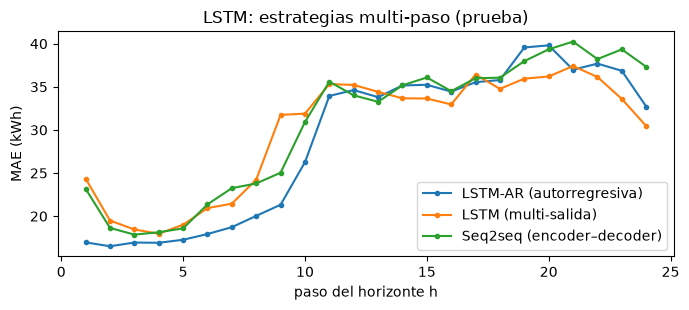

      LSTM-AR       LSTM    Seq2seq
1   16.959999  24.350000  23.170000
6   17.930000  20.940001  21.370001
12  34.619999  35.220001  34.009998
18  35.790001  34.759998  36.060001
24  32.720001  30.450001  37.330002

,MAE,RMSE,WAPE,MAPE,MASE,MASE_xmas,MASE_H168,train_s,infer_s
LSTM-AR,28.792,97.826,0.078,0.096,0.895,1.543,NaN,324.745,0.586
LSTM,29.820,98.227,0.080,0.105,0.945,1.571,NaN,273.153,0.482
Seq2seq,30.579,100.701,0.082,0.107,0.948,1.489,NaN,283.462,0.581


In [23]:
test_torch("LSTM", best_lstm, "Recurrente", "multi-salida", "calendario")
test_torch("LSTM-AR", "LSTMAR-best", "Recurrente", "autorregresiva", "calendario")
test_torch("Seq2seq", "Seq2seq-best", "Encoder–decoder", "encoder–decoder", "calendario (decoder)")
fig, ax = plt.subplots(figsize=(7, 3.2))
for name in ["LSTM-AR", "LSTM", "Seq2seq"]:
    ax.plot(range(1, H + 1), by_step(FCS[name]).MAE, marker=".", label=f"{name} ({REG[name]['estrategia']})")
ax.set(xlabel="paso del horizonte h", ylabel="MAE (kWh)", title="LSTM: estrategias multi-paso (prueba)")
ax.legend(); plt.tight_layout(); plt.savefig(FIGS / "estrategias.png", dpi=150); plt.show()
print(pd.DataFrame({n: by_step(FCS[n]).MAE for n in ["LSTM-AR", "LSTM", "Seq2seq"]}).iloc[[0, 5, 11, 17, 23]].round(2))
show(["LSTM-AR", "LSTM", "Seq2seq"])

### Tabla de iteraciones y curvas de pérdida

In [24]:
def iter_table():
    rows = []
    for name, it in ITERS.items():
        c = {"L": L, "months": 30, "norm": "series", **it["cfg"]}
        rows.append({"iteración": name, "arq": it["arch"], "L": c["L"], "H": c.get("H", H), "meses": c["months"] or 30,
                     "norm": c["norm"], "hidden": c.get("hidden", "—"), "capas": c.get("layers", "—"),
                     "dropout": c.get("dropout", "—"), "lr": c.get("lr", 1e-3), "batch": c.get("batch", 512),
                     "epochs": it["history"][-1]["epoch"], "params": it["n_params"][0], "entrenables": it["n_params"][1],
                     "s/epoch": round(it["epoch_s"], 1), "train_s": round(it["train_s"]), "infer_s (92 orig.)": round(it["infer_s"], 2),
                     "mem_pico_MB": round(it["peak_mem_mb"]), "val_MAE": round(it["val"]["MAE"], 2), "val_MASE": round(it["val"]["MASE"], 3)})
    return pd.DataFrame(rows).set_index("iteración")

IT = iter_table()
IT.to_csv(RESULTS / "iteraciones.csv")
IT

,arq,L,H,meses,norm,hidden,capas,dropout,lr,batch,epochs,params,entrenables,s/epoch,train_s,infer_s (92 orig.),mem_pico_MB,val_MAE,val_MASE
iteración,,,,,,,,,,,,,,,,,,,
LSTM-base,LSTM,168,24,30,series,128,2,0.1,0.001,512,15,209880,209880,32.9,497,1.21,7425,31.389999,0.991
LSTM-L48,LSTM,48,24,30,series,128,2,0.1,0.001,512,15,209880,209880,8.7,131,0.34,8279,31.120001,0.991
LSTM-L336,LSTM,336,24,30,series,128,2,0.1,0.001,512,15,209880,209880,124.2,1865,1.44,14529,30.930000,0.992
LSTM-3m,LSTM,168,24,3,series,128,2,0.1,0.001,512,10,209880,209880,23.9,239,0.94,7293,36.990002,1.098
LSTM-12m,LSTM,168,24,12,series,128,2,0.1,0.001,512,15,209880,209880,22.5,337,0.71,7293,31.350000,0.996
LSTM-global,LSTM,168,24,30,global,128,2,0.1,0.001,512,15,209880,209880,21.8,328,0.72,7293,39.560001,1.546
LSTM-revin,LSTM,168,24,30,revin,128,2,0.1,0.001,512,15,209882,209882,21.0,315,0.64,7302,31.180000,0.977
LSTM-h256,LSTM,168,24,30,series,256,2,0.1,0.001,512,15,808920,808920,99.0,1486,1.51,14551,29.809999,0.946
LSTM-lr3e-3,LSTM,168,24,30,series,128,2,0.1,0.003,512,15,209880,209880,18.2,273,0.54,7454,29.360001,0.940


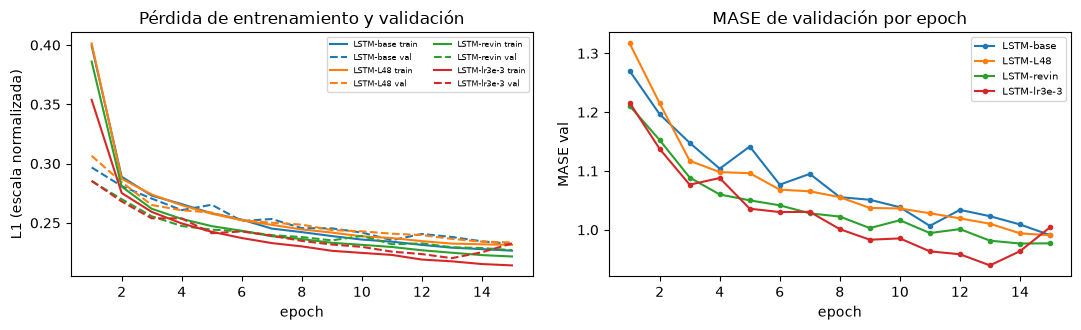

LSTM: correlación de Spearman entre pérdida final de train y MASE de val: -0.14
             train_loss  val_MASE
LSTM-global       0.049     1.546
LSTM-3m           0.213     1.098
LSTM-lr3e-3       0.214     0.940
LSTM-h256         0.216     0.946
LSTM-12m          0.221     0.996
LSTM-revin        0.222     0.977
LSTM-base         0.227     0.991
LSTM-L336         0.230     0.992
LSTM-L48          0.231     0.991
LSTM-b1024        0.236     1.036


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for name in ["LSTM-base", "LSTM-L48", "LSTM-revin", "LSTM-lr3e-3"]:
    hist = pd.DataFrame(ITERS[name]["history"])
    l, = ax[0].plot(hist.epoch, hist.train_loss, label=f"{name} train")
    ax[0].plot(hist.epoch, hist.val_loss, ls="--", color=l.get_color(), label=f"{name} val")
    ax[1].plot(hist.epoch, hist.val_MASE, color=l.get_color(), marker=".", label=name)
ax[0].set(xlabel="epoch", ylabel="L1 (escala normalizada)", title="Pérdida de entrenamiento y validación"); ax[0].legend(fontsize=6, ncol=2)
ax[1].set(xlabel="epoch", ylabel="MASE val", title="MASE de validación por epoch"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIGS / "curvas.png", dpi=150); plt.show()

final = pd.DataFrame({n: {"train_loss": it["history"][-1]["train_loss"], "val_MASE": it["val"]["MASE"]}
                      for n, it in ITERS.items() if it["arch"] == "LSTM"}).T
print("LSTM: correlación de Spearman entre pérdida final de train y MASE de val:",
      final.train_loss.corr(final.val_MASE, method="spearman").round(2))
print(final.sort_values("train_loss").round(3))

### Modelos lineales y MLP en prueba

Para cada arquitectura se lleva a prueba su mejor configuración de validación. DLinear y NLinear también se re-entrenan con
H = 168 para el MASE semanal.

In [26]:
for arch, fam, cov in [("DLinear", "Lineal", "no"), ("NLinear", "Lineal", "no"), ("MLP", "MLP", "calendario")]:
    b = best_of(arch + "-")
    test_torch(arch, b, fam, "multi-salida", cov)
    print(arch, "<-", b)
for arch in ["DLinear", "NLinear"]:
    cfg = {**ITERS[best_of(arch + "-")]["cfg"], "H": 168}
    iterate(f"{arch}-H168", arch, **cfg)
    res = cached(f"bt_{arch}_H168", lambda: backtest(load_iter(f"{arch}-H168"), origins_for(168), 168, fit=False))
    register(arch, res, "Lineal", H_=168)
show()

DLinear <- DLinear-L336-3m
NLinear <- NLinear-L168
MLP <- MLP-L336


DLinear-H168     epochs  8 | val MAE   32.76 | val MASE 1.051 |    14 s | params 113,232


NLinear-H168     epochs 11 | val MAE   31.34 | val MASE 1.036 |    11 s | params 28,392


,MAE,RMSE,WAPE,MAPE,MASE,MASE_xmas,MASE_H168,train_s,infer_s
MLP,27.922,92.142,0.075,0.096,0.876,1.534,NaN,25.898,0.106
LightGBM,27.566,95.983,0.074,0.094,0.878,1.727,1.081,221.702,20.747
LSTM-AR,28.792,97.826,0.078,0.096,0.895,1.543,NaN,324.745,0.586
DLinear,28.513,94.661,0.077,0.103,0.902,1.948,1.037,10.780,0.527
NLinear,28.783,96.011,0.078,0.104,0.908,1.882,1.027,6.243,0.057
MSTL,29.822,99.278,0.080,0.104,0.931,2.044,1.083,0.000,340.868
LSTM,29.820,98.227,0.080,0.105,0.945,1.571,NaN,273.153,0.482
Seq2seq,30.579,100.701,0.082,0.107,0.948,1.489,NaN,283.462,0.581
SNaive24,32.511,118.684,0.088,0.120,1.040,2.261,1.208,0.000,11.779
SNaive168,33.585,116.377,0.091,0.114,1.124,1.647,1.129,0.000,18.002


### 5.3 Modelo local contra global

El mejor modelo propio en validación se re-entrena por separado para 10 clientes (semilla fija), cada uno solo con sus
propias ventanas, y se compara el MASE de prueba en esos 10 clientes contra el modelo global.

In [27]:
own = {k: v for k, v in ITERS.items() if not k.endswith("H168")}
best_own = min(own, key=lambda k: own[k]["val"]["MASE"])
print("mejor modelo propio en validación:", best_own, ITERS[best_own]["arch"], ITERS[best_own]["cfg"])
LOCAL10 = np.sort(np.random.default_rng(SEED).choice(N, 10, replace=False))
glob_name = ITERS[best_own]["arch"]                                # nombre con el que se registró en prueba

def local_runs():
    out = {}
    for i in LOCAL10:
        m = TorchModel(ITERS[best_own]["arch"], series=[i], **ITERS[best_own]["cfg"])
        m.fit(TRAIN_END, VAL_END)
        P = m.predict(TEST_ORIGINS, H)["y_hat"][:, 0]                 # (92, H)
        y = Y.values[Y.index.get_indexer(TEST_ORIGINS)[:, None] + np.arange(H), i]
        out[CLIENTS[i]] = {"MASE_local": np.abs(P - y).mean() / SCALE.iloc[i], "epochs": m.history[-1]["epoch"]}
    return out

loc = pd.DataFrame(cached("local_vs_global", local_runs)).T
pcg = per_client(FCS[glob_name])
loc["MASE_global"] = pcg.loc[loc.index, "MASE"]
loc["media_kWh"] = means[loc.index].round(1)
loc["mejora_global_%"] = (100 * (1 - loc.MASE_global / loc.MASE_local)).round(1)
print(loc.round(3))
print("MASE medio en los 10 clientes -> local:", loc.MASE_local.mean().round(3), "| global:", loc.MASE_global.mean().round(3))

mejor modelo propio en validación: NLinear-L168 NLinear {'lr': 0.003, 'L': 168}
        MASE_local  epochs  MASE_global  media_kWh  mejora_global_%
MT_051       0.734    14.0        0.749       54.6             -2.0
MT_052       0.744    15.0        0.743       36.0              0.1
MT_097       0.594    11.0        0.853      190.5            -43.6
MT_192       0.900    12.0        0.928      458.7             -3.0
MT_256       0.898    12.0        0.877      142.5              2.3
MT_281       0.771    13.0        0.769      120.5              0.3
MT_287       0.823    15.0        0.824      153.7             -0.1
MT_326       0.886    13.0        0.889      240.9             -0.4
MT_356       0.155    15.0        0.152      112.7              2.0
MT_360       0.852    15.0        0.893      512.1             -4.8
MASE medio en los 10 clientes -> local: 0.736 | global: 0.768


### Modelos de librería: NeuralForecast

N-HiTS, TCN, PatchTST, TFT y DeepAR con la misma ventana L = 168, H = 24, `scaler_type="robust"` (normalización por
ventana), hasta 1,500 pasos con early stopping sobre el bloque de validación (`val_size` = 2,208 h) y MPS. DeepAR es
probabilístico (Student-t, intervalo del 80 % = P10–P90; el pronóstico puntual es la mediana).

**Covariables (iteración en validación).** En la primera corrida todos recibían el calendario como `futr_exog_list` y
N-HiTS (val MASE 1.30) y DeepAR (1.40) quedaron peor que el seasonal naive. Con la normalización por ventana la red
puede usar el mes como atajo para el nivel, que cambia de un año a otro. Por eso N-HiTS, TCN y DeepAR se entrenan con y
sin calendario y se queda la variante con menor MASE de **validación** (la prueba solo se reporta para esa). PatchTST no
admite covariables futuras en NeuralForecast y TFT (≈3 h por entrenamiento) se deja con calendario, que filtra con sus
redes de selección de variables.

`predict()` respeta el protocolo sin re-entrenar: arma una serie nueva por (origen, cliente) con las 192 h previas al
origen y llama una sola vez a `nf.predict` con el calendario futuro (`futr_df`). Como los modelos son globales y
normalizan cada ventana, el resultado es el mismo que pronosticar desde la serie completa cortada en el origen.

In [28]:
import logging
from neuralforecast import NeuralForecast
from neuralforecast.models import NHITS, TCN, PatchTST, TFT, DeepAR
from neuralforecast.losses.pytorch import DistributionLoss
for lg in ("pytorch_lightning", "lightning", "lightning.pytorch", "lightning.fabric", "neuralforecast"):
    logging.getLogger(lg).setLevel(logging.ERROR)

EXOG = list(CAL.columns)
NF_CTX = L + 24

def nf_long(Yw):
    return long_df(Yw).join(CAL, on="ds")

def nf_kw(seed=SEED, **kw):
    base = dict(h=H, input_size=L, max_steps=1500, val_check_steps=100, early_stop_patience_steps=5,
                scaler_type="robust", batch_size=32, windows_batch_size=256, learning_rate=1e-3, random_seed=seed,
                accelerator=DEVICE.type, enable_progress_bar=False, enable_model_summary=False, logger=False)
    return {**base, **kw}

class NFModel:
    """Adaptador de un modelo de NeuralForecast al protocolo fit/predict."""

    def __init__(self, make, months=None, seed=SEED):
        self.make, self.months, self.seed = make, months, seed

    def fit(self, train_end, val_end):
        start = train_end + pd.Timedelta("1h") - pd.DateOffset(months=self.months) if self.months else TRAIN_START
        self.nf = NeuralForecast(models=[self.make(self.seed)], freq="h")
        self.nf.fit(nf_long(Y.loc[start:val_end]), val_size=len(Y.loc[train_end:val_end]) - 1)
        self.n_params = count_params(self.nf.models[0])

    def predict(self, origins, H):
        t_o = Y.index.get_indexer(origins)
        ids = np.array([f"{k:03d}|{c}" for k in range(len(t_o)) for c in CLIENTS])
        past = t_o[:, None] + np.arange(-NF_CTX, 0)
        hist = pd.DataFrame({"unique_id": np.repeat(ids, NF_CTX), "ds": Y.index[np.repeat(past, N, axis=0).ravel()],
                             "y": Y.values[past].transpose(0, 2, 1).ravel()}).join(CAL, on="ds")
        futr = pd.DataFrame({"unique_id": np.repeat(ids, H),
                             "ds": Y.index[np.repeat(t_o[:, None] + np.arange(H), N, axis=0).ravel()]}).join(CAL, on="ds")
        p = self.nf.predict(df=hist, futr_df=futr).sort_values(["unique_id", "ds"])
        assert (p.unique_id.values[::H] == ids).all()
        name = type(self.nf.models[0]).__name__
        get = lambda col: p[col].values.reshape(len(t_o), N, H)
        if f"{name}-lo-80" in p:                                   # DeepAR: mediana + intervalo 80 % (P10, P90)
            med = get(f"{name}-median")
            return {"y_hat": med, "q10": get(f"{name}-lo-80"), "q50": med, "q90": get(f"{name}-hi-80")}
        return {"y_hat": get(name)}

NF_MODELS = {                                  # nombre -> (fábrica(seed, exog), familia, estrategia, variantes de exog)
    "NHITS": (lambda s, ex: NHITS(**nf_kw(s, futr_exog_list=ex)), "Residual (MLP)", "multi-salida", (True, False)),
    "TCN": (lambda s, ex: TCN(**nf_kw(s, futr_exog_list=ex, kernel_size=2, dilations=[1, 2, 4, 8, 16, 32, 64, 128],
                                      encoder_hidden_size=128)), "Convolucional", "multi-salida", (True, False)),
    "PatchTST": (lambda s, ex: PatchTST(**nf_kw(s, patch_len=24, stride=12, hidden_size=128, n_heads=8)),
                 "Atención", "multi-salida", (False,)),
    "TFT": (lambda s, ex: TFT(**nf_kw(s, futr_exog_list=ex, hidden_size=64)), "Atención", "multi-salida", (True,)),
    # inference_windows_batch_size: por defecto (-1) valida con todas las ventanas a la vez (~45 GB en MPS)
    "DeepAR": (lambda s, ex: DeepAR(**nf_kw(s, futr_exog_list=ex, lstm_hidden_size=128, inference_windows_batch_size=1024,
                                            loss=DistributionLoss("StudentT", level=[80]))),
               "Probabilístico", "autorregresiva (muestreo)", (True, False)),
}

def nf_run(name, months=None, test=True, key=None, exog=True):
    """Entrena una vez (train + early stopping en val), mide validación y, si test, pronostica la prueba una vez."""
    make = lambda s: NF_MODELS[name][0](s, EXOG if exog else None)
    key = (key or name) + ("" if exog else "-noexog")
    def go():
        m = NFModel(make, months)
        val = backtest(m, VAL_ORIGINS)
        out = {"val": evaluate(val["fc"]), "train_s": val["train_s"]}
        if test:
            out["test"] = backtest(m, TEST_ORIGINS, fit=False)
            out["test"].update(train_s=val["train_s"], n_params=m.n_params)
        return out
    out = cached(f"nf_{key}", go)
    free_mps()
    print(f"{key:20s} val MASE {out['val']['MASE']:.3f} | train {out['train_s']:.0f} s")
    return {**out, "make": make}

NF_OUT, EXOG_VAL = {}, {}
for name, (_, family, strategy, variants) in NF_MODELS.items():
    runs = {ex: nf_run(name, exog=ex) for ex in variants}
    ex = min(runs, key=lambda e: runs[e]["val"]["MASE"])                # selección solo con validación
    EXOG_VAL[name] = {("con calendario" if e else "sin calendario"): r["val"]["MASE"] for e, r in runs.items()}
    NF_OUT[name] = out = runs[ex]
    register(name, out["test"], family, strategy=strategy, covariates="calendario" if ex else "no", hw=HARDWARE)
    VAL_MASE[name], MAKE[name] = out["val"]["MASE"], lambda seed=SEED, make=out["make"]: NFModel(make, seed=seed)
print("MASE de validación por variante:")
print(pd.DataFrame(EXOG_VAL).T.round(3))
show()

2026-10-31 02:01:18,981	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-10-31 02:01:19,409	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


Seed set to 42


NHITS                val MASE 1.304 | train 470 s


Seed set to 42


NHITS-noexog         val MASE 0.808 | train 207 s
TCN                  val MASE 1.007 | train 405 s


TCN-noexog           val MASE 0.886 | train 381 s
PatchTST-noexog      val MASE 0.925 | train 409 s
TFT                  val MASE 0.825 | train 11179 s


Seed set to 42


DeepAR               val MASE 1.404 | train 1481 s


DeepAR-noexog        val MASE 1.278 | train 422 s
MASE de validación por variante:
          con calendario  sin calendario
NHITS              1.304           0.808
TCN                1.007           0.886
PatchTST             NaN           0.925
TFT                0.825             NaN
DeepAR             1.404           1.278


,MAE,RMSE,WAPE,MAPE,MASE,MASE_xmas,MASE_H168,pinball,cov80,train_s,infer_s
NHITS,26.084,91.008,0.070,0.090,0.830,1.513,NaN,NaN,NaN,206.917,0.948
TFT,26.782,92.307,0.072,0.091,0.849,1.642,NaN,NaN,NaN,11178.530,8.246
MLP,27.922,92.142,0.075,0.096,0.876,1.534,NaN,NaN,NaN,25.898,0.106
LightGBM,27.566,95.983,0.074,0.094,0.878,1.727,1.081,NaN,NaN,221.702,20.747
TCN,28.718,95.941,0.077,0.100,0.893,1.748,NaN,NaN,NaN,381.354,0.943
LSTM-AR,28.792,97.826,0.078,0.096,0.895,1.543,NaN,NaN,NaN,324.745,0.586
DLinear,28.513,94.661,0.077,0.103,0.902,1.948,1.037,NaN,NaN,10.780,0.527
NLinear,28.783,96.011,0.078,0.104,0.908,1.882,1.027,NaN,NaN,6.243,0.057
MSTL,29.822,99.278,0.080,0.104,0.931,2.044,1.083,NaN,NaN,0.000,340.868
LSTM,29.820,98.227,0.080,0.105,0.945,1.571,NaN,NaN,NaN,273.153,0.482


### Chronos-Bolt (zero-shot)

`amazon/chronos-bolt-small` sin entrenamiento: recibe las últimas 2,048 h (≈12 semanas) de cada cliente en kWh y devuelve
los cuantiles 0.1/0.5/0.9 de las próximas H horas. El pronóstico puntual es la mediana. Solo se mide el tiempo de
inferencia; cargar los pesos no cuenta como entrenamiento.

In [29]:
from chronos import BaseChronosPipeline

class ChronosModel:
    def __init__(self, model_id="amazon/chronos-bolt-small", ctx=2048):
        self.model_id, self.ctx = model_id, ctx

    def fit(self, train_end, val_end):
        # CPU: en MPS, con la RAM compartida casi llena, la inferencia se quedaba sin memoria o en swap
        self.pipe = BaseChronosPipeline.from_pretrained(self.model_id, device_map="cpu", torch_dtype=torch.float32)
        self.n_params = count_params(self.pipe.model)

    def predict(self, origins, H, bs=256):                      # bs=1024 x 2048 de contexto agota la memoria de MPS
        t_o = Y.index.get_indexer(origins)
        ctx = Y.values[t_o[:, None] + np.arange(-self.ctx, 0)].transpose(0, 2, 1).reshape(-1, self.ctx)
        qs = [self.pipe.predict_quantiles(torch.tensor(ctx[i:i + bs], dtype=torch.float32), prediction_length=H,
                                          quantile_levels=list(QS))[0].float().cpu().numpy()
              for i in range(0, len(ctx), bs)]
        q = np.concatenate(qs).reshape(len(t_o), N, H, len(QS))
        return {"y_hat": q[..., 1], "q10": q[..., 0], "q50": q[..., 1], "q90": q[..., 2]}

def chronos_runs():
    cm = ChronosModel()
    val = backtest(cm, VAL_ORIGINS)
    test = backtest(cm, TEST_ORIGINS, fit=False)
    test["n_params"] = cm.n_params
    return {"val": evaluate(val["fc"]), "test": test, "h168": backtest(cm, origins_for(168), 168, fit=False)}

CHR = cached("chronos", chronos_runs)
register("Chronos-Bolt", CHR["test"], "Fundacional", L_=2048, strategy="directa (cuantiles)", covariates="no",
         hw="Apple M5 Pro (24 GB), CPU")
register("Chronos-Bolt", CHR["h168"], "Fundacional", H_=168)
REG["Chronos-Bolt"]["train_s"] = np.nan                         # zero-shot: solo inferencia
VAL_MASE["Chronos-Bolt"] = CHR["val"]["MASE"]
print("Chronos val MASE", round(CHR["val"]["MASE"], 3), "| parámetros", f"{CHR['test']['n_params'][0]:,}")
show()

W1031 02:18:35.156000 83790 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 143/143 [00:00<00:00, 10914.12it/s]

Chronos val MASE 0.76 | parámetros 47,718,016


,MAE,RMSE,WAPE,MAPE,MASE,MASE_xmas,MASE_H168,pinball,cov80,train_s,infer_s
Chronos-Bolt,24.334,84.896,0.066,0.084,0.785,1.498,0.951,8.193,0.798,NaN,39.666
NHITS,26.084,91.008,0.070,0.090,0.830,1.513,NaN,NaN,NaN,206.917,0.948
TFT,26.782,92.307,0.072,0.091,0.849,1.642,NaN,NaN,NaN,11178.530,8.246
MLP,27.922,92.142,0.075,0.096,0.876,1.534,NaN,NaN,NaN,25.898,0.106
LightGBM,27.566,95.983,0.074,0.094,0.878,1.727,1.081,NaN,NaN,221.702,20.747
TCN,28.718,95.941,0.077,0.100,0.893,1.748,NaN,NaN,NaN,381.354,0.943
LSTM-AR,28.792,97.826,0.078,0.096,0.895,1.543,NaN,NaN,NaN,324.745,0.586
DLinear,28.513,94.661,0.077,0.103,0.902,1.948,1.037,NaN,NaN,10.780,0.527
NLinear,28.783,96.011,0.078,0.104,0.908,1.882,1.027,NaN,NaN,6.243,0.057
MSTL,29.822,99.278,0.080,0.104,0.931,2.044,1.083,NaN,NaN,0.000,340.868


### Pronóstico probabilístico

DeepAR y Chronos entregan P10, P50 y P90. Pinball loss promedio sobre los tres cuantiles (kWh) y cobertura empírica del
intervalo P10–P90 (nominal 80 %).

                 MAE   MASE  pinball  cov80
DeepAR        40.495  1.302   14.701  0.557
Chronos-Bolt  24.334  0.785    8.193  0.798


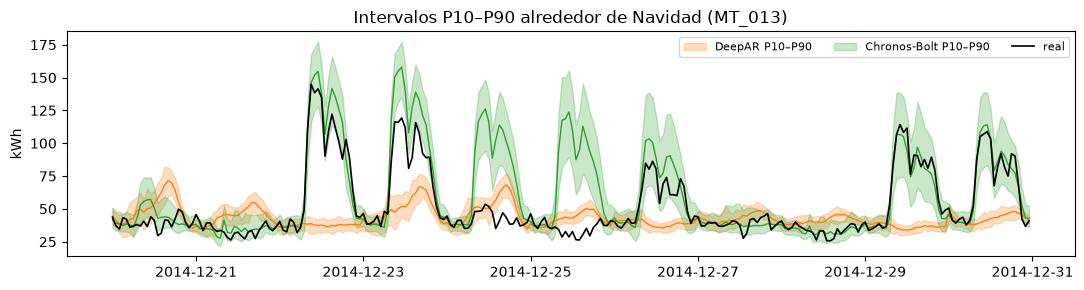

In [30]:
prob = pd.DataFrame({n: REG[n] for n in ["DeepAR", "Chronos-Bolt"]}).T[["MAE", "MASE", "pinball", "cov80"]].astype(float)
print(prob.round(3))
fig, ax = plt.subplots(figsize=(11, 3))
cid = CLIENTS[0]
for n, c in [("DeepAR", "C1"), ("Chronos-Bolt", "C2")]:
    f = FCS[n][(FCS[n].unique_id == cid) & FCS[n].ds.between("2014-12-20", "2014-12-30 23:00")]
    ax.fill_between(f.ds, f.q10, f.q90, alpha=0.25, color=c, label=f"{n} P10–P90")
    ax.plot(f.ds, f.q50, color=c, lw=1)
ax.plot(f.ds, f.y, color="k", lw=1.2, label="real")
ax.set(title=f"Intervalos P10–P90 alrededor de Navidad ({cid})", ylabel="kWh"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(FIGS / "probabilistico.png", dpi=150); plt.show()

### Historia de entrenamiento (3, 12 y 30 meses) en validación

Datos para la gráfica (3) de §6: MASE de validación según los meses de historia para seasonal naive (no depende de la
historia), LightGBM, DLinear, LSTM y PatchTST, con Chronos (zero-shot) como referencia.

In [31]:
def lgbm_val(months):
    m = lgbm if months is None else LGBMRecursive(months=months)
    return evaluate(backtest(m, VAL_ORIGINS, fit=months is not None)["fc"])["MASE"]

HIST = pd.DataFrame({
    "SNaive24": {mo: cached("val_SNaive24", lambda: evaluate(backtest(SFModel(SeasonalNaive(24)), VAL_ORIGINS)["fc"])["MASE"])
                 for mo in (3, 12, 30)},
    "LightGBM": {mo: cached(f"val_lgbm_{mo}", lambda: lgbm_val(None if mo == 30 else mo)) for mo in (3, 12, 30)},
    "DLinear": {3: ITERS["DLinear-L336-3m"]["val"]["MASE"], 12: ITERS["DLinear-L336-12m"]["val"]["MASE"],
                30: ITERS["DLinear-L336"]["val"]["MASE"]},
    "LSTM": {3: ITERS["LSTM-3m"]["val"]["MASE"], 12: ITERS["LSTM-12m"]["val"]["MASE"], 30: ITERS["LSTM-base"]["val"]["MASE"]},
    "PatchTST": {3: nf_run("PatchTST", 3, False, "PatchTST-3m", exog=False)["val"]["MASE"],
                 12: nf_run("PatchTST", 12, False, "PatchTST-12m", exog=False)["val"]["MASE"],
                 30: NF_OUT["PatchTST"]["val"]["MASE"]},
})
HIST.index.name = "meses"
HIST.round(3)

Seed set to 42


Seed set to 42


PatchTST-3m-noexog   val MASE 0.934 | train 83 s


PatchTST-12m-noexog  val MASE 0.926 | train 93 s


,SNaive24,LightGBM,DLinear,LSTM,PatchTST
meses,,,,,
3,0.95,0.897,0.856,1.098,0.934
12,0.95,0.847,0.868,0.996,0.926
30,0.95,0.834,0.864,0.991,0.925


### Reentrenamiento mensual

El mejor modelo de deep learning (por MASE de validación) y LightGBM se re-entrenan al inicio de octubre, noviembre y
diciembre con ventana expandible (validación = los 92 días previos a cada corte) y pronostican los orígenes de ese mes.
Los baselines de StatsForecast ya se re-ajustan en **cada** origen (son locales), así que reentrenarlos al inicio de cada
mes no cambia nada: su protocolo ya es más frecuente que el mensual.

In [32]:
DL_FAMILIES = ("MLP", "Recurrente", "Encoder–decoder", "Residual (MLP)", "Convolucional", "Atención", "Probabilístico")
dl = {n: v for n, v in VAL_MASE.items() if REG[n]["familia"] in DL_FAMILIES}
BEST_DL = min(dl, key=dl.get)
print("val MASE de los modelos de DL:", {k: round(v, 3) for k, v in sorted(dl.items(), key=lambda kv: kv[1])})
print("mejor DL en validación:", BEST_DL)

def monthly(make):
    fcs, tr = [], 0.0
    for m0 in pd.to_datetime(["2014-10-01", "2014-11-01", "2014-12-01"]):
        o = TEST_ORIGINS[(TEST_ORIGINS >= m0) & (TEST_ORIGINS < m0 + pd.offsets.MonthBegin(1))]
        res = backtest(make(), o, H, train_end=m0 - pd.Timedelta(days=92) - pd.Timedelta("1h"),
                       val_end=m0 - pd.Timedelta("1h"))
        fcs.append(res["fc"])
        tr += res["train_s"]
    return {"fc": pd.concat(fcs, ignore_index=True), "train_s": tr}

RETRAIN = {BEST_DL: cached(f"monthly_{BEST_DL}", lambda: monthly(MAKE[BEST_DL])),
           "LightGBM": cached("monthly_LightGBM", lambda: monthly(LGBMRecursive))}
rt = pd.DataFrame({n: {"MASE una vez": REG[n]["MASE"], "MASE mensual": evaluate(r["fc"])["MASE"],
                       "MAE una vez": REG[n]["MAE"], "MAE mensual": evaluate(r["fc"])["MAE"],
                       "train_s una vez": REG[n]["train_s"], "train_s mensual (3 fits)": r["train_s"]}
                   for n, r in RETRAIN.items()}).T
rt.astype(float).round(3)

Seed set to 42


val MASE de los modelos de DL: {'NHITS': np.float64(0.808), 'TFT': np.float64(0.825), 'MLP': np.float64(0.857), 'TCN': np.float64(0.886), 'LSTM-AR': np.float64(0.9), 'PatchTST': np.float64(0.925), 'LSTM': np.float64(0.94), 'Seq2seq': np.float64(0.949), 'DeepAR': np.float64(1.278)}
mejor DL en validación: NHITS


Seed set to 42


Seed set to 42


,MASE una vez,MASE mensual,MAE una vez,MAE mensual,train_s una vez,train_s mensual (3 fits)
NHITS,0.830,0.833,26.084,26.131,206.917,610.160
LightGBM,0.878,0.874,27.566,27.470,221.702,246.981


### Sensibilidad a la semilla (mejor modelo de DL, 3 semillas)

In [33]:
def seed_run(seed):
    if seed == SEED:
        return REG[BEST_DL]["MASE"]
    return evaluate(backtest(MAKE[BEST_DL](seed=seed))["fc"])["MASE"]

SEEDS = {s: cached(f"seed_{BEST_DL}_{s}", lambda: seed_run(s)) for s in (SEED, 1, 2)}
print(BEST_DL, {s: round(v, 4) for s, v in SEEDS.items()},
      f"| MASE = {np.mean(list(SEEDS.values())):.3f} ± {np.std(list(SEEDS.values()), ddof=1):.3f}")

Seed set to 1


Seed set to 2


NHITS {42: np.float64(0.83), 1: np.float64(0.8291), 2: np.float64(0.8316)} | MASE = 0.830 ± 0.001


## 6. Comparación de resultados

Mejor configuración de cada modelo, evaluada una sola vez sobre los 92 orígenes de prueba, ordenada por MASE.
`train_s` = entrenamiento (para los modelos locales de StatsForecast el ajuste ocurre en cada origen y está en `infer_s`;
Chronos no entrena). `infer_s` = pronóstico de los 92 orígenes × 100 clientes.

In [34]:
COLS = ["familia", "L", "estrategia", "covariables", "params", "entrenables", "train_s", "infer_s", "hardware",
        "MAE", "RMSE", "WAPE", "MAPE", "MASE", "MASE_H168", "MASE_xmas", "pinball", "cov80"]
TABLE = pd.DataFrame(REG).T.reindex(columns=COLS).sort_values("MASE")
TABLE.to_csv(RESULTS / "comparacion.csv")
num = ["MAE", "RMSE", "WAPE", "MAPE", "MASE", "MASE_H168", "MASE_xmas", "pinball", "cov80", "train_s", "infer_s"]
TABLE[num] = TABLE[num].astype(float).round(3)
TABLE

,familia,L,estrategia,covariables,params,entrenables,train_s,infer_s,hardware,MAE,RMSE,WAPE,MAPE,MASE,MASE_H168,MASE_xmas,pinball,cov80
Chronos-Bolt,Fundacional,2048,directa (cuantiles),no,47718016,47718016,NaN,39.666,"Apple M5 Pro (24 GB), CPU",24.334,84.896,0.066,0.084,0.785,0.951,1.498,8.193,0.798
NHITS,Residual (MLP),168,multi-salida,no,2817570,2817570,206.917,0.948,"Apple M5 Pro (24 GB), MPS",26.084,91.008,0.070,0.090,0.830,NaN,1.513,NaN,NaN
TFT,Atención,168,multi-salida,calendario,479692,479692,11178.530,8.246,"Apple M5 Pro (24 GB), MPS",26.782,92.307,0.072,0.091,0.849,NaN,1.642,NaN,NaN
MLP,MLP,336,multi-salida,calendario,1737752,1737752,25.898,0.106,"Apple M5 Pro (24 GB), MPS",27.922,92.142,0.075,0.096,0.876,NaN,1.534,NaN,NaN
LightGBM,Árboles,168,recursiva,calendario,754193,754193,221.702,20.747,CPU,27.566,95.983,0.074,0.094,0.878,1.081,1.727,NaN,NaN
TCN,Convolucional,168,multi-salida,no,251353,251353,381.354,0.943,"Apple M5 Pro (24 GB), MPS",28.718,95.941,0.077,0.100,0.893,NaN,1.748,NaN,NaN
LSTM-AR,Recurrente,168,autorregresiva,calendario,202881,202881,324.745,0.586,"Apple M5 Pro (24 GB), MPS",28.792,97.826,0.078,0.096,0.895,NaN,1.543,NaN,NaN
DLinear,Lineal,336,multi-salida,no,16176,16176,10.780,0.527,"Apple M5 Pro (24 GB), MPS",28.513,94.661,0.077,0.103,0.902,1.037,1.948,NaN,NaN
NLinear,Lineal,168,multi-salida,no,4056,4056,6.243,0.057,"Apple M5 Pro (24 GB), MPS",28.783,96.011,0.078,0.104,0.908,1.027,1.882,NaN,NaN
MSTL,Baseline,1008,directa (local),no,0,0,0.000,340.868,CPU,29.822,99.278,0.080,0.104,0.931,1.083,2.044,NaN,NaN


In [35]:
snaive = REG["SNaive24"]["MASE"]
print(f"mejor modelo: {TABLE.index[0]} (MASE {TABLE.MASE.iloc[0]:.3f}) | seasonal naive 24 h: {snaive:.3f} "
      f"-> mejora {100 * (1 - TABLE.MASE.iloc[0] / snaive):.1f} %")
fc_all = FCS[TABLE.index[0]]
assert np.allclose(by_step(fc_all, "hour").MAE.values, by_step(fc_all).MAE.values)   # origen 00:00: hora = h - 1
print("con orígenes a las 00:00, el error por hora del día coincide con el error por paso h (hora = h − 1)")

mejor modelo: Chronos-Bolt (MASE 0.785) | seasonal naive 24 h: 1.040 -> mejora 24.5 %
con orígenes a las 00:00, el error por hora del día coincide con el error por paso h (hora = h − 1)


### Gráficas

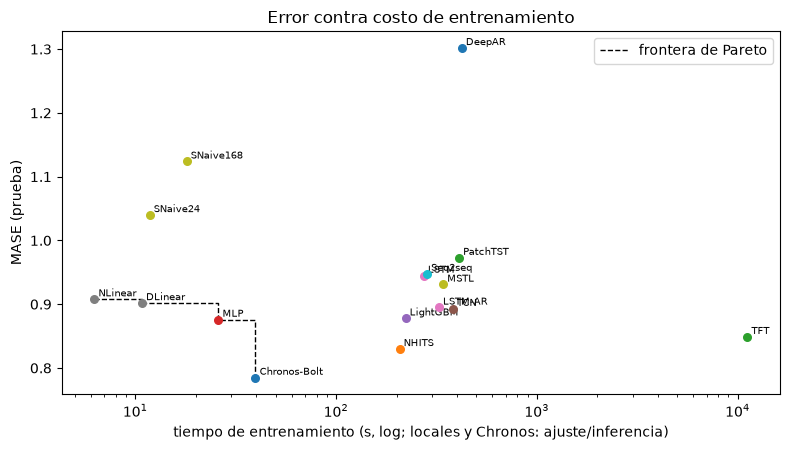

frontera de Pareto: ['NLinear', 'DLinear', 'MLP', 'Chronos-Bolt']


In [36]:
fam_color = {f: f"C{i}" for i, f in enumerate(TABLE.familia.unique())}
fig, ax = plt.subplots(figsize=(8, 4.6))
t = TABLE.train_s.where(TABLE.train_s > 0, TABLE.infer_s)          # modelos sin entrenamiento: costo de ajuste/inferencia
pts = pd.DataFrame({"t": t, "MASE": TABLE.MASE}).drop(index="Naive")
for n, r in pts.iterrows():
    ax.scatter(r.t, r.MASE, color=fam_color[TABLE.familia[n]], s=30, zorder=3)
    ax.annotate(n, (r.t, r.MASE), fontsize=7, xytext=(3, 2), textcoords="offset points")
front = pts.sort_values("t")
front = front[front.MASE <= front.MASE.cummin()]
ax.step(front.t, front.MASE, where="post", color="k", lw=1, ls="--", label="frontera de Pareto")
ax.set(xscale="log", xlabel="tiempo de entrenamiento (s, log; locales y Chronos: ajuste/inferencia)", ylabel="MASE (prueba)",
       title="Error contra costo de entrenamiento")
ax.legend(); plt.tight_layout(); plt.savefig(FIGS / "pareto.png", dpi=150); plt.show()
print("frontera de Pareto:", list(front.index))

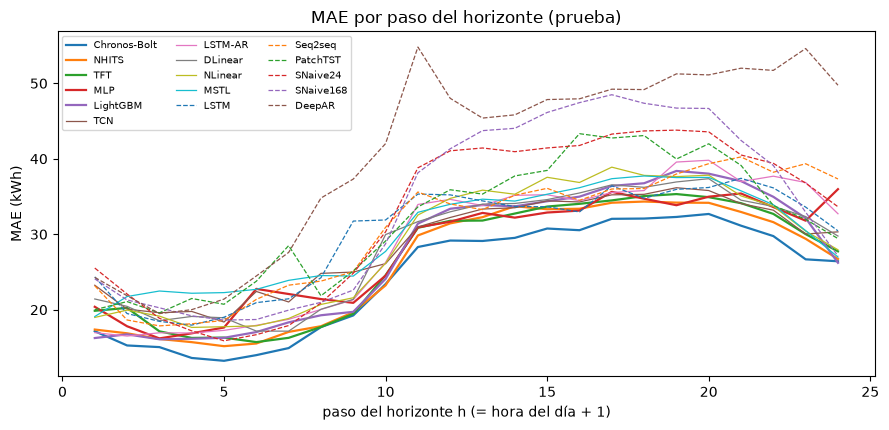

{'SNaive168': 1.1299999952316284, 'LSTM': 1.25, 'TCN': 1.2999999523162842, 'SNaive24': 1.3200000524520874, 'DLinear': 1.3899999856948853, 'TFT': 1.399999976158142, 'MSTL': 1.409999966621399, 'NLinear': 1.4700000286102295, 'PatchTST': 1.4700000286102295, 'Chronos-Bolt': 1.5399999618530273, 'NHITS': 1.5399999618530273, 'LightGBM': 1.6100000143051147, 'Seq2seq': 1.6100000143051147, 'MLP': 1.7599999904632568, 'LSTM-AR': 1.9299999475479126, 'DeepAR': 2.049999952316284}


In [37]:
STEP = pd.DataFrame({n: by_step(FCS[n]).MAE for n in TABLE.index if n != "Naive"})
STEP.to_csv(RESULTS / "mae_por_paso.csv")
fig, ax = plt.subplots(figsize=(9, 4.4))
for i, n in enumerate(STEP.columns):
    ax.plot(STEP.index, STEP[n], lw=1.6 if i < 5 else 0.9, ls="-" if i < 10 else "--", label=n)
ax.set(xlabel="paso del horizonte h (= hora del día + 1)", ylabel="MAE (kWh)", title="MAE por paso del horizonte (prueba)")
ax.legend(ncol=3, fontsize=7); plt.tight_layout(); plt.savefig(FIGS / "mae_por_paso.png", dpi=150); plt.show()
print((STEP.iloc[-1] / STEP.iloc[0]).round(2).sort_values().to_dict())     # crecimiento del error h=24 vs h=1

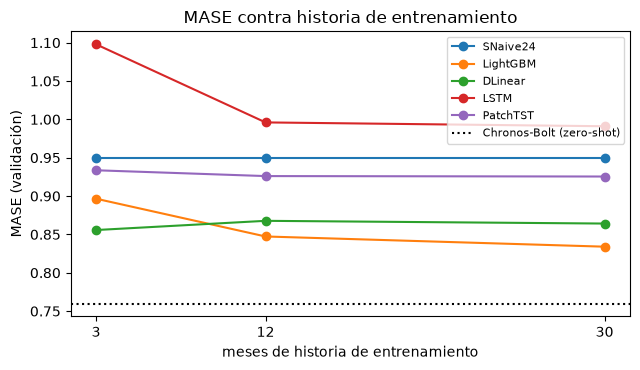

In [38]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for n in HIST:
    ax.plot(HIST.index, HIST[n], marker="o", label=n)
ax.axhline(VAL_MASE["Chronos-Bolt"], color="k", ls=":", label="Chronos-Bolt (zero-shot)")
ax.set(xticks=[3, 12, 30], xlabel="meses de historia de entrenamiento", ylabel="MASE (validación)",
       title="MASE contra historia de entrenamiento")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIGS / "historia.png", dpi=150); plt.show()

### Navidad y Año Nuevo

Semana del 22 al 28 de diciembre (incluye Nochebuena y Navidad) y error medio por día alrededor de los feriados.

            Chronos-Bolt  NHITS   TFT   MLP  LightGBM   TCN  SNaive24  \
ds                                                                      
2014-12-18          0.69   0.69  0.69  0.79      0.75  0.73      0.77   
2014-12-23          0.79   0.74  0.80  0.87      0.80  0.82      0.82   
2014-12-24          1.72   1.71  1.75  1.73      1.77  1.70      1.81   
2014-12-25          3.87   4.34  4.31  4.23      4.42  4.75      4.70   
2014-12-26          1.75   1.26  1.31  1.22      2.50  2.19      5.23   
2014-12-31          1.40   1.42  1.76  1.62      1.49  1.36      1.86   

            SNaive168  
ds                     
2014-12-18       0.89  
2014-12-23       1.08  
2014-12-24       1.70  
2014-12-25       5.36  
2014-12-26       0.54  
2014-12-31       1.44  


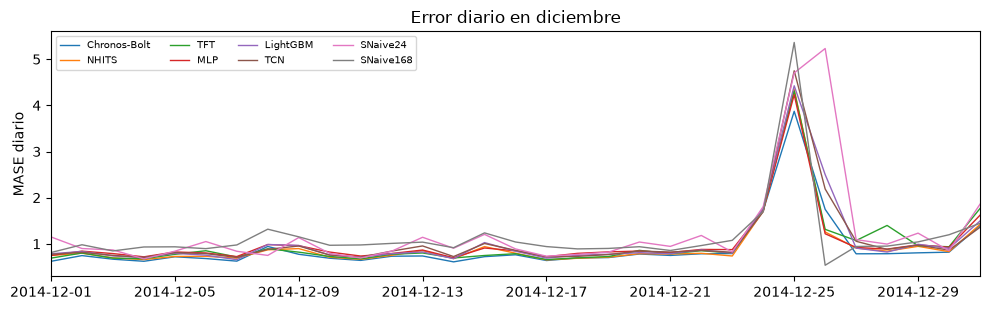

In [39]:
top = [n for n in TABLE.index[:6]] + ["SNaive24", "SNaive168"]
daily_err = pd.DataFrame({n: (FCS[n].assign(sae=(FCS[n].y_hat - FCS[n].y).abs() / FCS[n].unique_id.map(SCALE).astype(float))
                              .groupby(FCS[n].ds.dt.date).sae.mean()) for n in dict.fromkeys(top)})
print(daily_err.loc[pd.to_datetime(["2014-12-18", "2014-12-23", "2014-12-24", "2014-12-25", "2014-12-26",
                                    "2014-12-31"]).date].round(2))
fig, ax = plt.subplots(figsize=(10, 3.2))
for n in daily_err:
    ax.plot(pd.to_datetime(daily_err.index), daily_err[n], lw=1, label=n)
ax.set(xlim=(pd.Timestamp("2014-12-01"), pd.Timestamp("2014-12-31")), ylabel="MASE diario", title="Error diario en diciembre")
ax.legend(ncol=4, fontsize=7); plt.tight_layout(); plt.savefig(FIGS / "navidad.png", dpi=150); plt.show()

### Archivos de resultados

In [40]:
out = pd.concat([f[["unique_id", "ds", "y_hat"]].assign(modelo=n) for n, f in FCS.items()], ignore_index=True)
out = out[["unique_id", "ds", "modelo", "y_hat"]].astype({"unique_id": str, "modelo": "category"})
out.to_parquet(RESULTS / "pronosticos_prueba.parquet", index=False)
pd.concat({n: per_client(f) for n, f in FCS.items()}, names=["modelo"]).round(4).to_csv(RESULTS / "metricas_por_cliente.csv")
print(out.shape, out.modelo.nunique(), "modelos |", (RESULTS / "pronosticos_prueba.parquet").stat().st_size / 2 ** 20, "MB")
print(sorted(p.name for p in RESULTS.iterdir()))

(3753600, 4) 17 modelos | 15.478734016418457 MB
['comparacion.csv', 'iteraciones.csv', 'mae_por_paso.csv', 'metricas_por_cliente.csv', 'pronosticos_prueba.parquet']
